# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

### Registro de cambios respecto del notebook base

| Qué | Detalle | Por qué |
|---|---|---|
| Constantes de la sección 0 | **Sin cambios** (`SIZES`, `SEEDS`, `MAX_EPOCHS`, `PATIENCE`, `BATCH`, `AUG_COPIES`, `SEED_SPLIT = 42`, `SEEDS_FINAL`) | Se ejecuta el notebook tal como viene |
| Sección 5 (MLP vs CNN) | Se agrega la columna `caida_std`: desvío entre semillas de la caída por traslación | El notebook base solo da la media y no permite decir si la diferencia entre modelos supera el ruido |
| Celdas de análisis (✏️) | Cada pregunta tiene debajo una celda de código que **genera el texto desde las variables de la corrida** (`md(...)`) | Las conclusiones tienen que coincidir con los outputs; si se cambia algo y se vuelve a ejecutar, los números del texto se actualizan solos |
| Sección 9.1 (nueva) | Tres controles de sesgo/fuga que **solo usan train y val** (línea base solo con resolución o color, entrenamiento con la partición original con duplicados, augmentation antes del split) | Cuantificar los puntos del EDA y del análisis 3 que la consigna pide discutir |
| Sección 8 (test) | **Sin cambios**: se ejecuta una sola vez | Regla metodológica |
| Celda `md`/`pct`/`pts`/`umbral` (nueva, después de la configuración) | Utilidades para escribir los textos y regla de "diferencia real" | Una diferencia solo se considera real si supera el desvío entre semillas y el error estándar de la validación/test |


## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [4]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.15.0+cpu


In [5]:
# ---- utilidades para generar los textos de análisis a partir de los resultados ----
from IPython.display import Markdown, display
def md(t): display(Markdown(t))
def pct(x, d=0): return f"{100 * x:.{d}f} %"
def pts(x, d=1): return f"{100 * x:+.{d}f}"                 # diferencia en puntos porcentuales, con signo
def se_acc(p, n): return float(np.sqrt(p * (1 - p) / n))     # error estándar binomial de un accuracy
def umbral(sa, sb, p, n):
    # una diferencia solo se considera real si supera el desvío entre semillas de ambas configuraciones Y el error estándar de la validación/test
    return max(sa, sb, se_acc(p, n))
def veredicto(d, sa, sb, p, n):
    u = umbral(sa, sb, p, n)
    if abs(d) <= u: return "dentro del ruido"
    return "supera el umbral por poco (no concluyente con 3 semillas)" if abs(d) < 1.5 * u else "supera el ruido"

## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [6]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 11s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


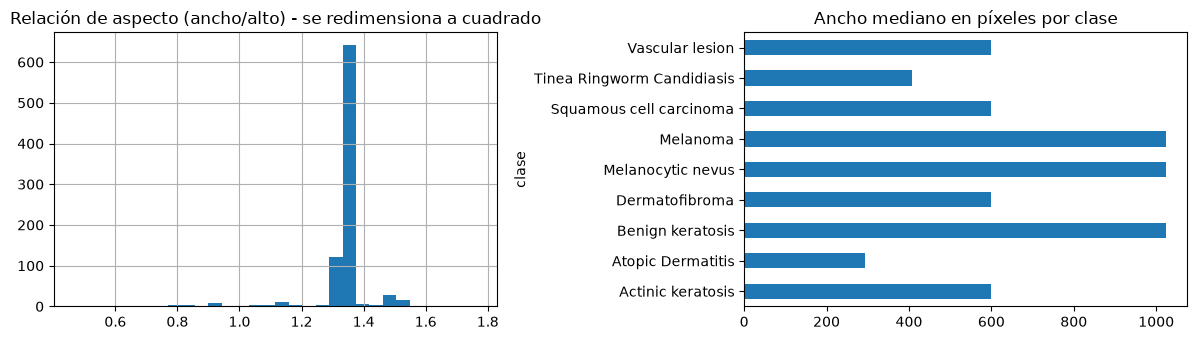

In [7]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

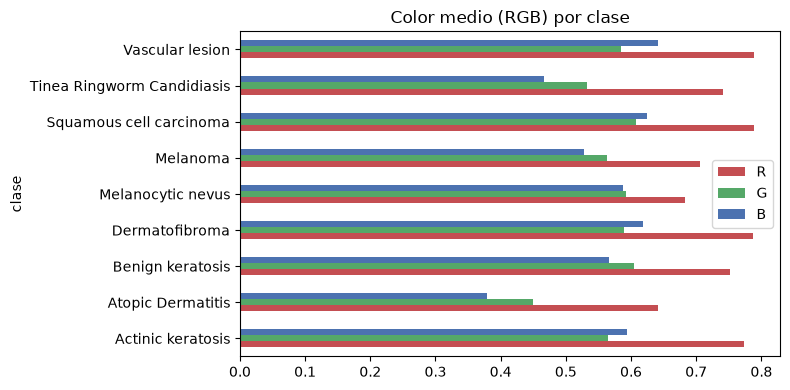

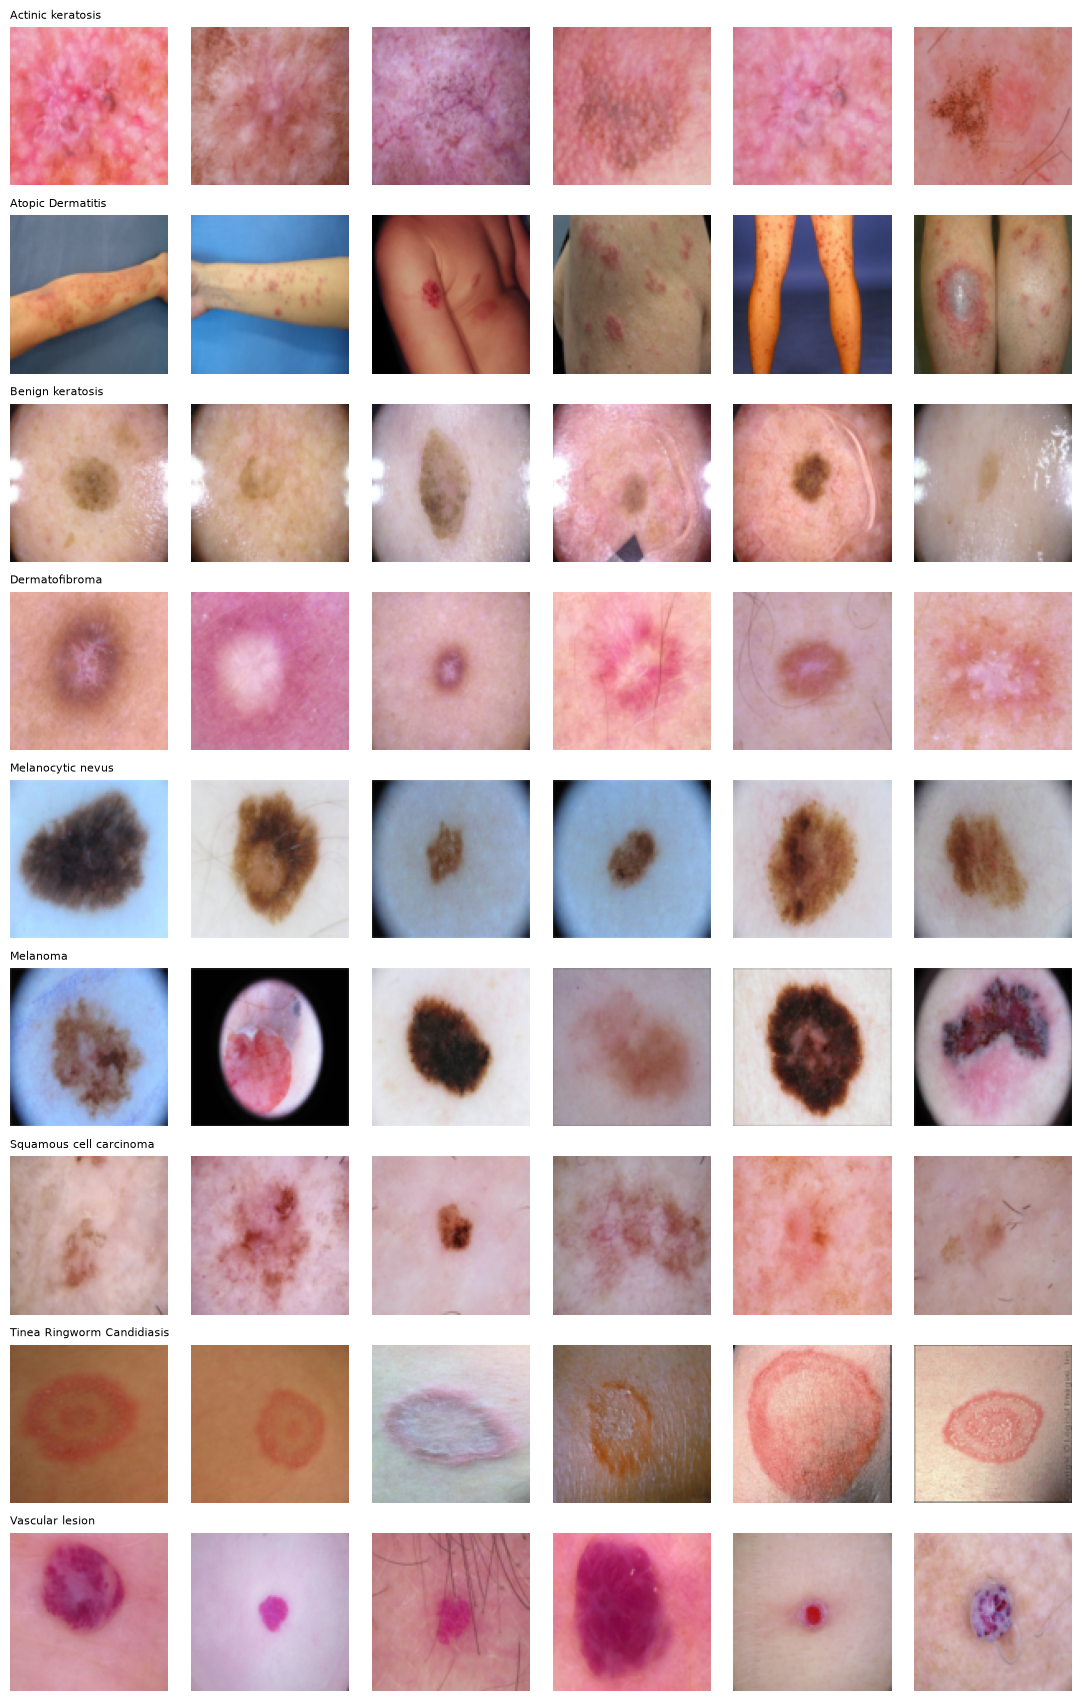

In [8]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [9]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

In [10]:
n_tot = len(df); cnt = df["clase"].value_counts(); orig = pd.crosstab(df["clase"], df["carpeta"])
frac_val = orig["val"] / orig.sum(axis=1)
ded = df.groupby("md5").head(1)["clase"].value_counts()
tr_md5 = set(df.loc[df["carpeta"] == "train", "md5"])
val_leak = df[(df["carpeta"] == "val") & df["md5"].isin(tr_md5)]; n_val0 = int((df["carpeta"] == "val").sum())
top_res = df.groupby("clase")["res"].agg(lambda s: (s.value_counts().index[0], float(s.value_counts(normalize=True).iloc[0])))
mono = [f"{c} ({r}, {pct(f)})" for c, (r, f) in top_res.items() if f >= 0.9]
mixed = [f"{c} ({pct(f)} en {r})" for c, (r, f) in top_res.items() if f < 0.9]
res_shared = df[df["res"].isin(df["res"].value_counts().head(5).index)].groupby("res")["clase"].nunique()
asp = df["aspecto"]; frac43 = float(((asp > 1.30) & (asp < 1.36)).mean())
rgb = mean_rgb.groupby("clase").mean(); bright = rgb.mean(axis=1).sort_values()
dup_cls = df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts()
md(f"""#### Observaciones del EDA (generadas a partir de los outputs de arriba)

**1. Desbalance.** Hay {n_tot} imágenes en {NUM_CLASSES} clases. La clase más chica es *{cnt.idxmin()}* ({cnt.min()} imágenes) y la más grande *{cnt.idxmax()}* ({cnt.max()}); el resto tiene 100. La razón entre la más grande y la más chica es {cnt.max() / cnt.min():.2f}:1: el desbalance es leve, pero existe, y *{cnt.idxmin()}* queda siempre con menos peso en la loss y menos ejemplos para validar. La partición original `train`/`val` no es proporcional: `val` tiene {int(orig['val'].min())}–{int(orig['val'].max())} imágenes por clase (casi balanceado), mientras `train` va de {int(orig['train'].min())} a {int(orig['train'].max())}; la fracción que cae en `val` va de {pct(frac_val.min())} a {pct(frac_val.max())} (la más alta es *{frac_val.idxmax()}*). Al eliminar los duplicados el desbalance crece: *{ded.idxmin()}* baja a {ded.min()} y *{ded.index[-2]}* a {ded.iloc[-2]}, contra 100 de las demás (razón {ded.max() / ded.min():.2f}:1). Con el split 60/20/20 eso deja {int(round(ded.min() * .6))}/{int(round(ded.min() * .2))}/{int(round(ded.min() * .2))} imágenes de *{ded.idxmin()}* en train/val/test: las métricas de esa clase son las más inestables.

**2. Resolución, aspecto y color.** La resolución depende fuertemente de la clase: {len(mono)} de {NUM_CLASSES} clases tienen ≥ 90 % de sus imágenes en una única resolución exacta ({'; '.join(mono)}); {'; '.join(mixed)} reparten sus imágenes entre varias resoluciones. Una misma resolución la comparten varias clases (p. ej. {', '.join(f'{r} → {n} clases' for r, n in res_shared.sort_values(ascending=False).head(2).items())}), así que no identifica la clase por sí sola, pero sí a algunas (*Atopic Dermatitis*, la única con imágenes de 294×222). La relación de aspecto casi no distingue: {pct(frac43)} de las imágenes está entre 1.30 y 1.36 (≈ 4:3), por lo que redimensionar a cuadrado las deforma todas más o menos igual. En color, las clases más oscuras (promedio RGB) son {', '.join(f'*{c}* ({v:.2f})' for c, v in bright.head(2).items())} y las más claras {', '.join(f'*{c}* ({v:.2f})' for c, v in bright.tail(2).items())}; la menor componente azul es la de *{rgb['B'].idxmin()}* ({rgb['B'].min():.2f}). **Riesgo:** la resolución original y el tono medio dependen de la fuente de adquisición (cámara, dermatoscopio, centro) y no de la lesión. Al redimensionar a 32/64/96 px se pierde la resolución absoluta, pero no necesariamente la nitidez, el ruido de compresión ni los dominantes de color. Un modelo podría aprender "de qué fuente viene" en vez de la morfología de la lesión (*shortcut learning*) y su accuracy sobreestimaría lo que generaliza a imágenes de otra fuente. En la sección 9.1 se mide cuánto predicen la clase solo la resolución y solo el color medio.

**3. Duplicados.** Hay {len(dup_groups)} grupos de imágenes idénticas (MD5), {len(cross)} de ellos repetidos entre `train` y `val`; solo aparecen en {', '.join(f'*{c}* ({n})' for c, n in dup_cls.items())}. No hay conflictos de etiqueta y el hash perceptual no encuentra casi-duplicados no idénticos ({len(near_not_exact)} pares). Importan porque una imagen que está en train y en val no mide generalización sino memorización: {len(val_leak)} de las {n_val0} imágenes de la `val` original ({pct(len(val_leak) / n_val0)}) tienen una copia exacta en train, concentradas en {', '.join(f'*{c}* ({n} de {int(orig.loc[c, "val"])} de val)' for c, n in val_leak['clase'].value_counts().items())}. Si no se eliminaran, la `val_acc` quedaría inflada, sobre todo en esas clases, y la selección de modelos/early stopping se haría sobre una métrica optimista. En la sección 9.1 se cuantifica entrenando con la partición original.""")

#### Observaciones del EDA (generadas a partir de los outputs de arriba)

**1. Desbalance.** Hay 878 imágenes en 9 clases. La clase más chica es *Tinea Ringworm Candidiasis* (76 imágenes) y la más grande *Atopic Dermatitis* (102); el resto tiene 100. La razón entre la más grande y la más chica es 1.34:1: el desbalance es leve, pero existe, y *Tinea Ringworm Candidiasis* queda siempre con menos peso en la loss y menos ejemplos para validar. La partición original `train`/`val` no es proporcional: `val` tiene 20–21 imágenes por clase (casi balanceado), mientras `train` va de 56 a 81; la fracción que cae en `val` va de 20 % a 26 % (la más alta es *Tinea Ringworm Candidiasis*). Al eliminar los duplicados el desbalance crece: *Tinea Ringworm Candidiasis* baja a 64 y *Atopic Dermatitis* a 80, contra 100 de las demás (razón 1.56:1). Con el split 60/20/20 eso deja 38/13/13 imágenes de *Tinea Ringworm Candidiasis* en train/val/test: las métricas de esa clase son las más inestables.

**2. Resolución, aspecto y color.** La resolución depende fuertemente de la clase: 5 de 9 clases tienen ≥ 90 % de sus imágenes en una única resolución exacta (Actinic keratosis (600x450, 100 %); Atopic Dermatitis (294x222, 100 %); Dermatofibroma (600x450, 100 %); Squamous cell carcinoma (600x450, 100 %); Vascular lesion (600x450, 100 %)); Benign keratosis (74 % en 1024x764); Melanocytic nevus (79 % en 1024x768); Melanoma (56 % en 1024x768); Tinea Ringworm Candidiasis (3 % en 300x213) reparten sus imágenes entre varias resoluciones. Una misma resolución la comparten varias clases (p. ej. 600x450 → 4 clases, 1022x767 → 2 clases), así que no identifica la clase por sí sola, pero sí a algunas (*Atopic Dermatitis*, la única con imágenes de 294×222). La relación de aspecto casi no distingue: 87 % de las imágenes está entre 1.30 y 1.36 (≈ 4:3), por lo que redimensionar a cuadrado las deforma todas más o menos igual. En color, las clases más oscuras (promedio RGB) son *Atopic Dermatitis* (0.49), *Tinea Ringworm Candidiasis* (0.58) y las más claras *Vascular lesion* (0.67), *Squamous cell carcinoma* (0.67); la menor componente azul es la de *Atopic Dermatitis* (0.38). **Riesgo:** la resolución original y el tono medio dependen de la fuente de adquisición (cámara, dermatoscopio, centro) y no de la lesión. Al redimensionar a 32/64/96 px se pierde la resolución absoluta, pero no necesariamente la nitidez, el ruido de compresión ni los dominantes de color. Un modelo podría aprender "de qué fuente viene" en vez de la morfología de la lesión (*shortcut learning*) y su accuracy sobreestimaría lo que generaliza a imágenes de otra fuente. En la sección 9.1 se mide cuánto predicen la clase solo la resolución y solo el color medio.

**3. Duplicados.** Hay 34 grupos de imágenes idénticas (MD5), 33 de ellos repetidos entre `train` y `val`; solo aparecen en *Atopic Dermatitis* (22), *Tinea Ringworm Candidiasis* (12). No hay conflictos de etiqueta y el hash perceptual no encuentra casi-duplicados no idénticos (0 pares). Importan porque una imagen que está en train y en val no mide generalización sino memorización: 33 de las 181 imágenes de la `val` original (18 %) tienen una copia exacta en train, concentradas en *Atopic Dermatitis* (21 de 21 de val), *Tinea Ringworm Candidiasis* (12 de 20 de val). Si no se eliminaran, la `val_acc` quedaría inflada, sobre todo en esas clases, y la selección de modelos/early stopping se haría sobre una métrica optimista. En la sección 9.1 se cuantifica entrenando con la partición original.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [11]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

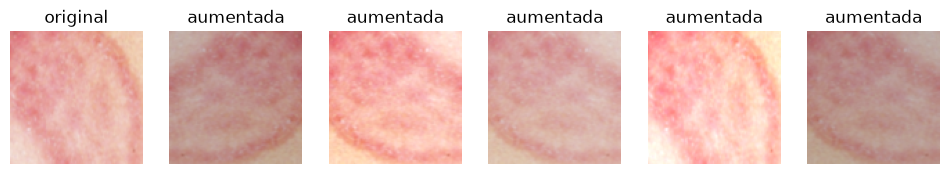

In [12]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [13]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [14]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

In [15]:
# ---- verificación numérica de lo que se explica abajo (si algo no coincide con la tabla, el assert falla) ----
def conv_out(h, k, p): return h + 2 * p - k + 1
k, cin, cout = 3, 16, 32
p_conv2 = k * k * cin * cout                                     # filtros: k*k*cin pesos por canal de salida; sin sesgo porque bias=not use_bn
assert p_conv2 == int(tr.loc[4, "params"]) and tr.loc[4, "tipo"] == "Conv2d"
fs = 64 // 2 ** 3; c3 = 64
p_lin = c3 * fs * fs * 128 + 128                                 # in_features*out_features + sesgos
assert p_lin == int(tr.loc[13, "params"]) and tr.loc[13, "salida"] == (128,)
total = int(tr["params"].sum()); share_lin = p_lin / total
assert int(tr.loc[1, "params"]) == 2 * 16                        # BatchNorm: γ y β por canal
n_bn = int(tr[tr["tipo"] == "BatchNorm2d"]["params"].sum())
conv_rows = tr[tr["tipo"] == "Conv2d"]
macs = [int(r["salida"][1] * r["salida"][2] * r["params"]) for _, r in conv_rows.iterrows()]   # multiplicaciones-acumulaciones por conv (sin sesgo)
vol = [int(np.prod(tr.loc[i, "salida"])) for i in conv_rows.index]                              # tamaño del mapa de activación de cada conv
# campo receptivo paso a paso
r, j, pasos = 1, 1, []
for b in range(3):
    r += (3 - 1) * j; pasos.append(f"conv {b + 1}: r = {r}")
    if b < 2: r += 1 * j; j *= 2; pasos.append(f"pool {b + 1}: r = {r}, salto = {j}")
assert r == rf_full(3, 3)
# tamaños sin padding (floor en el pooling)
h, sin_pad = 64, []
for b in range(3):
    h = conv_out(h, 3, 0); sin_pad.append(h); h //= 2; sin_pad.append(h)
md(f"""#### Explicación del código convolucional (cada número se verifica contra la tabla de arriba)

**1. `padding=kernel // 2`.** Una convolución con kernel k y padding p produce una salida de lado `H + 2p − k + 1`. Con k = 3 y p = 1 queda `H + 2 − 3 + 1 = H`: el alto y el ancho no cambian. En la tabla, la salida de cada `Conv2d` es (16, 64, 64), (32, 32, 32) y (64, 16, 16): el lado es el mismo que el de su entrada (solo cambia la cantidad de canales) y la única reducción espacial la hace el `MaxPool2d`. Con `padding=0` la convolución perdería `k − 1 = 2` píxeles por bloque: el lado iría {' → '.join(str(v) for v in [64] + sin_pad)} (cada conv resta 2 y cada pool divide por 2), la cabeza recibiría un mapa de {sin_pad[-1]}×{sin_pad[-1]} en vez de {fs}×{fs} y los bordes de la imagen aportarían menos a la salida (un píxel del borde entra en una sola ventana). Con `kernel // 2` el tamaño solo depende del pooling y el kernel puede cambiarse (3, 5, 7) sin tocar `fs`.

**2. `MaxPool2d(2)`.** Toma el máximo de cada ventana de 2×2 sin solapar: divide el alto y el ancho por 2 (64 → 32 → 16 → 8 en la tabla), conserva la cantidad de canales y no tiene parámetros (0 en la tabla). Se queda con la activación más fuerte de cada vecindario (¿apareció el patrón en esta zona?) y descarta la posición exacta dentro de la ventana, lo que da algo de invariancia a traslaciones chicas y reduce el costo de las capas siguientes. Después de 3 pooling el lado es `size // 2**3 = {fs}` (división entera: si `size` no fuera múltiplo de 8 se descartarían filas/columnas), y por eso la cabeza recibe `{c3} × {fs} × {fs} = {c3 * fs * fs}` valores (`Flatten` en la tabla: ({c3 * fs * fs},)).

**3. Parámetros.** La segunda `Conv2d` (16 → 32 canales, k = 3) tiene `3·3·16·32 = {p_conv2}` pesos y ningún sesgo (`bias=False` porque hay BatchNorm): coincide con la tabla ({int(tr.loc[4, 'params'])}). Con sesgo serían {p_conv2 + cout}. La primera `Linear` de la cabeza tiene `{c3 * fs * fs}·128 + 128 = {p_lin}` parámetros, también igual a la tabla. De los {total} parámetros totales, la `Linear` tiene el {pct(share_lin, 1)}: domina porque es **densa** (cada una de las {c3 * fs * fs} entradas se conecta con cada una de las 128 neuronas) mientras que los filtros convolucionales se **comparten** en todas las posiciones: las tres convoluciones juntas suman solo {int(conv_rows['params'].sum())} pesos. Es la misma razón por la que la MLP es tan grande (análisis 1).

**4. `bias=not use_bn`.** La BatchNorm resta la media de cada canal calculada sobre el batch y luego aplica `γ·x̂ + β`: cualquier constante que sumara el sesgo de la convolución se elimina al restar la media, y el `β` de la BatchNorm cumple el rol del sesgo. Tener ambos sería redundante (parámetros que el modelo no puede identificar por separado). Se ahorran {16 + 32 + 64} parámetros; la BatchNorm agrega 2 por canal (`γ` y `β`), por ejemplo {int(tr.loc[1, 'params'])} para 16 canales, {n_bn} en total.

**5. `filters * 2 ** b`.** Cada pooling reduce a la cuarta parte la cantidad de posiciones espaciales (÷2 en alto y en ancho) y se duplica la cantidad de canales: el volumen del mapa de activación baja a la mitad por bloque ({' → '.join(str(v) for v in vol)} valores en la tabla), y la cantidad de multiplicaciones de las convoluciones 2 y 3 queda igual ({macs[1]:,} y {macs[2]:,}, contra {macs[0]:,} de la primera), porque ×4 en pesos por convolución se compensa con ÷4 en posiciones. La idea es cambiar resolución espacial por variedad de detectores: las primeras capas detectan patrones simples en muchas posiciones y las siguientes combinan esos patrones en rasgos más abstractos, que hacen falta en mayor variedad.

**6. Campo receptivo (`rf_full`).** Cada conv suma `(k − 1)·salto` y cada pooling suma `1·salto` y duplica el salto: {'; '.join(pasos)}. Resultado: **{r} px**, igual a `rf_full(3, 3)`. En una imagen de 64 px es el {pct(r / 64)} del lado ({pct((r / 64) ** 2)} del área): cada unidad de la última convolución "ve" solo un recorte local; la forma global de la lesión (simetría, borde completo) solo se integra en la `Linear` de la cabeza, que mira todo el mapa de {fs}×{fs}.""")

#### Explicación del código convolucional (cada número se verifica contra la tabla de arriba)

**1. `padding=kernel // 2`.** Una convolución con kernel k y padding p produce una salida de lado `H + 2p − k + 1`. Con k = 3 y p = 1 queda `H + 2 − 3 + 1 = H`: el alto y el ancho no cambian. En la tabla, la salida de cada `Conv2d` es (16, 64, 64), (32, 32, 32) y (64, 16, 16): el lado es el mismo que el de su entrada (solo cambia la cantidad de canales) y la única reducción espacial la hace el `MaxPool2d`. Con `padding=0` la convolución perdería `k − 1 = 2` píxeles por bloque: el lado iría 64 → 62 → 31 → 29 → 14 → 12 → 6 (cada conv resta 2 y cada pool divide por 2), la cabeza recibiría un mapa de 6×6 en vez de 8×8 y los bordes de la imagen aportarían menos a la salida (un píxel del borde entra en una sola ventana). Con `kernel // 2` el tamaño solo depende del pooling y el kernel puede cambiarse (3, 5, 7) sin tocar `fs`.

**2. `MaxPool2d(2)`.** Toma el máximo de cada ventana de 2×2 sin solapar: divide el alto y el ancho por 2 (64 → 32 → 16 → 8 en la tabla), conserva la cantidad de canales y no tiene parámetros (0 en la tabla). Se queda con la activación más fuerte de cada vecindario (¿apareció el patrón en esta zona?) y descarta la posición exacta dentro de la ventana, lo que da algo de invariancia a traslaciones chicas y reduce el costo de las capas siguientes. Después de 3 pooling el lado es `size // 2**3 = 8` (división entera: si `size` no fuera múltiplo de 8 se descartarían filas/columnas), y por eso la cabeza recibe `64 × 8 × 8 = 4096` valores (`Flatten` en la tabla: (4096,)).

**3. Parámetros.** La segunda `Conv2d` (16 → 32 canales, k = 3) tiene `3·3·16·32 = 4608` pesos y ningún sesgo (`bias=False` porque hay BatchNorm): coincide con la tabla (4608). Con sesgo serían 4640. La primera `Linear` de la cabeza tiene `4096·128 + 128 = 524416` parámetros, también igual a la tabla. De los 549273 parámetros totales, la `Linear` tiene el 95.5 %: domina porque es **densa** (cada una de las 4096 entradas se conecta con cada una de las 128 neuronas) mientras que los filtros convolucionales se **comparten** en todas las posiciones: las tres convoluciones juntas suman solo 23472 pesos. Es la misma razón por la que la MLP es tan grande (análisis 1).

**4. `bias=not use_bn`.** La BatchNorm resta la media de cada canal calculada sobre el batch y luego aplica `γ·x̂ + β`: cualquier constante que sumara el sesgo de la convolución se elimina al restar la media, y el `β` de la BatchNorm cumple el rol del sesgo. Tener ambos sería redundante (parámetros que el modelo no puede identificar por separado). Se ahorran 112 parámetros; la BatchNorm agrega 2 por canal (`γ` y `β`), por ejemplo 32 para 16 canales, 224 en total.

**5. `filters * 2 ** b`.** Cada pooling reduce a la cuarta parte la cantidad de posiciones espaciales (÷2 en alto y en ancho) y se duplica la cantidad de canales: el volumen del mapa de activación baja a la mitad por bloque (65536 → 32768 → 16384 valores en la tabla), y la cantidad de multiplicaciones de las convoluciones 2 y 3 queda igual (4,718,592 y 4,718,592, contra 1,769,472 de la primera), porque ×4 en pesos por convolución se compensa con ÷4 en posiciones. La idea es cambiar resolución espacial por variedad de detectores: las primeras capas detectan patrones simples en muchas posiciones y las siguientes combinan esos patrones en rasgos más abstractos, que hacen falta en mayor variedad.

**6. Campo receptivo (`rf_full`).** Cada conv suma `(k − 1)·salto` y cada pooling suma `1·salto` y duplica el salto: conv 1: r = 3; pool 1: r = 4, salto = 2; conv 2: r = 8; pool 2: r = 10, salto = 4; conv 3: r = 18. Resultado: **18 px**, igual a `rf_full(3, 3)`. En una imagen de 64 px es el 28 % del lado (8 % del área): cada unidad de la última convolución "ve" solo un recorte local; la forma global de la lesión (simetría, borde completo) solo se integra en la `Linear` de la cabeza, que mira todo el mapa de 8×8.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 7 | val_acc 0.615 | train_acc 0.662 | 1.58 s/época | total 49s


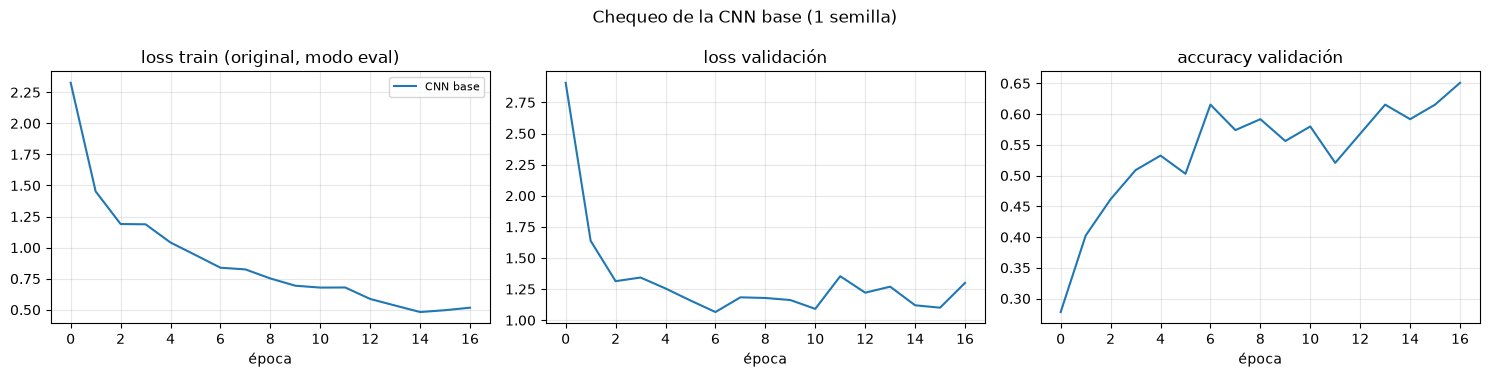

In [16]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion,caida_std
0,MLP 32px,1640201,0.4892,0.0056,0.6970,0.2078,4.0000,0.3255,0.4116,0.0776,0.0358
1,MLP 64px,6358793,0.5148,0.0302,0.6976,0.1828,7.6667,1.1811,0.4352,0.0796,0.0125
2,CNN 32px,156057,0.6312,0.0223,0.8162,0.1850,8.3333,0.4461,0.5819,0.0493,0.0074
3,CNN 64px,549273,0.6410,0.0283,0.7708,0.1297,11.6667,1.6170,0.5602,0.0809,0.0285


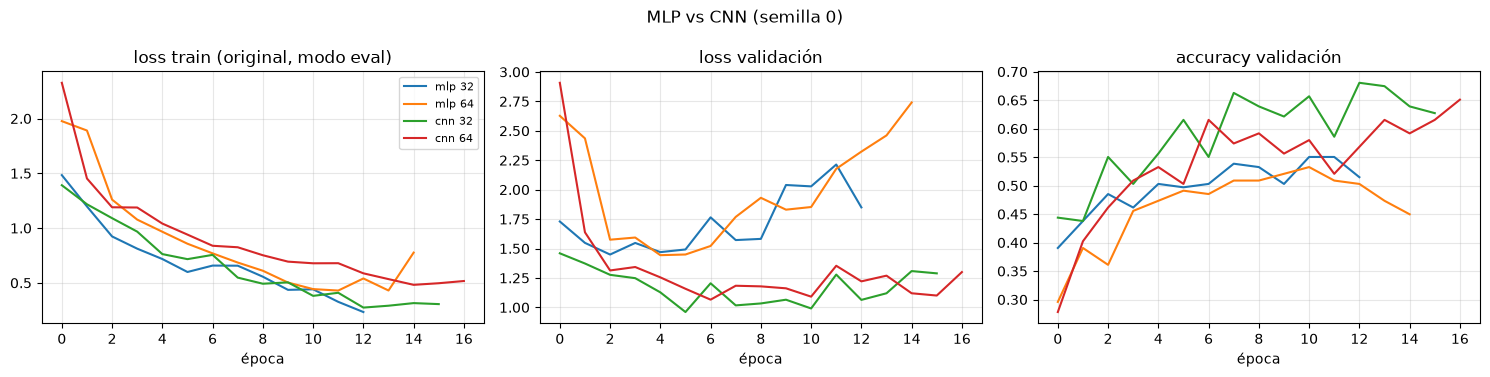

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [17]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted),
                     caida_std=np.std([c_ - s_ for c_, s_ in zip(clean, shifted)])))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

In [18]:
t1 = pd.DataFrame(rows).set_index("modelo"); nva = len(idx_va)
def macs_of(model, size):
    # multiplicaciones-acumulaciones de una pasada (solo conv y Linear)
    model.eval(); x = torch.zeros(1, 3, size, size); tot = 0
    for l in (list(model.features) + list(model.head) if isinstance(model, CNN) else list(model.net)):
        y = l(x)
        if isinstance(l, nn.Conv2d): tot += y.shape[2] * y.shape[3] * l.weight.numel()
        elif isinstance(l, nn.Linear): tot += l.weight.numel()
        x = y
    return tot
mac = {"MLP 32px": macs_of(MLP(32), 32), "MLP 64px": macs_of(MLP(64), 64), "CNN 32px": macs_of(CNN(32), 32), "CNN 64px": macs_of(CNN(64), 64)}
m32, m64, c32, c64 = (t1.loc[k] for k in ["MLP 32px", "MLP 64px", "CNN 32px", "CNN 64px"])
def cmp_txt(a, b, nombre_a, nombre_b):
    d = a["val_acc"] - b["val_acc"]; u = umbral(a["std"], b["std"], max(a["val_acc"], b["val_acc"]), nva)
    return f"a {a.name.split()[1]}: {nombre_a} {a['val_acc']:.3f} ± {a['std']:.3f} contra {nombre_b} {b['val_acc']:.3f} ± {b['std']:.3f} ({pts(d)} puntos; umbral de ruido {100 * u:.1f} puntos → {veredicto(d, a['std'], b['std'], max(a['val_acc'], b['val_acc']), nva)})"
l1_mlp = lambda s: 3 * s * s * 512 + 512                        # primera capa de la MLP: 3·s·s entradas × 512 neuronas + sesgos
assert l1_mlp(32) + 512 * 128 + 128 + 128 * NUM_CLASSES + NUM_CLASSES == int(m32["params"])
assert l1_mlp(64) == MLP(64).net[1].weight.numel() + MLP(64).net[1].bias.numel()
cnn224 = n_params(CNN(224)); conv_par = sum(p.numel() for n_, p in CNN(64).named_parameters() if n_.startswith("features"))
dr = {k: t1.loc[k] for k in t1.index}
def cmp_drop(a, b):
    d = b["caida_por_traslacion"] - a["caida_por_traslacion"]; u = max(a["caida_std"], b["caida_std"])
    return d, u
dc32, uc32 = cmp_drop(c32, m32); dc64, uc64 = cmp_drop(c64, m64)
cnn_menos = (dc32 > uc32) and (dc64 > uc64)
real64 = abs(c64["val_acc"] - m64["val_acc"]) > umbral(c64["std"], m64["std"], c64["val_acc"], nva)
real32 = abs(c32["val_acc"] - m32["val_acc"]) > umbral(c32["std"], m32["std"], c32["val_acc"], nva)
frase_real = ("la ventaja de la CNN supera el ruido entre semillas y el error estándar en las dos resoluciones" if (real64 and real32 and c64["val_acc"] > m64["val_acc"] and c32["val_acc"] > m32["val_acc"])
              else "no en todas las resoluciones la diferencia entre CNN y MLP supera el ruido: hay que leer la tabla con cuidado")
d_res_mlp, d_res_cnn = m64["val_acc"] - m32["val_acc"], c64["val_acc"] - c32["val_acc"]
frase_res = ("no supera el ruido" if (abs(d_res_mlp) <= umbral(m64["std"], m32["std"], m64["val_acc"], nva) and abs(d_res_cnn) <= umbral(c64["std"], c32["std"], c64["val_acc"], nva)) else "supera el ruido en al menos uno de los dos modelos")
md(f"""#### Análisis 1 - De la MLP a la CNN (generado a partir de la tabla de arriba, {nva} imágenes de validación)

**1. Comparación.** Parámetros: la CNN usa {int(c64['params']):,} contra {int(m64['params']):,} de la MLP a 64 px ({m64['params'] / c64['params']:.1f} veces menos) y {int(c32['params']):,} contra {int(m32['params']):,} a 32 px ({m32['params'] / c32['params']:.1f} veces menos). Val_acc (media ± desvío de 3 semillas): {cmp_txt(c64, m64, 'CNN', 'MLP')}; {cmp_txt(c32, m32, 'CNN', 'MLP')}. El error estándar binomial de la validación con {nva} imágenes es de ±{100 * se_acc(c64['val_acc'], nva):.1f} puntos, así que {frase_real}. La diferencia entre 32 y 64 px dentro de cada modelo ({pts(d_res_mlp)} puntos para la MLP, {pts(d_res_cnn)} para la CNN) {frase_res}.
La **brecha train-val** de la CNN ({100 * c64['brecha']:.1f} puntos a 64 px, {100 * c32['brecha']:.1f} a 32 px) {'no es menor' if c64['brecha'] >= m64['brecha'] - .02 else 'es menor'} que la de la MLP ({100 * m64['brecha']:.1f} y {100 * m32['brecha']:.1f}): la CNN gana por mejor val_acc, no por sobreajustar menos; ambas memorizan buena parte del train ({100 * c64['train_acc']:.0f} % y {100 * m64['train_acc']:.0f} % de accuracy de train a 64 px). **Época de convergencia** (mínimo de val_loss): CNN {c64['mejor_epoca']:.0f} (64 px) y {c32['mejor_epoca']:.0f} (32 px) contra MLP {m64['mejor_epoca']:.0f} y {m32['mejor_epoca']:.0f}: {'la MLP empieza a sobreajustar antes.' if (m64['mejor_epoca'] < c64['mejor_epoca'] and m32['mejor_epoca'] < c32['mejor_epoca']) else 'no hay un patrón claro entre modelos.'} **Tiempo por época:** a 64 px la CNN tarda {c64['t_epoca_s']:.2f} s contra {m64['t_epoca_s']:.2f} s de la MLP ({c64['t_epoca_s'] / m64['t_epoca_s']:.1f} veces), con {m64['params'] / c64['params']:.0f} veces menos parámetros: el tiempo depende de la cantidad de operaciones y no de la de parámetros, y una convolución reutiliza cada peso en todas las posiciones ({mac['CNN 64px'] / 1e6:.1f} M de multiplicaciones-acumulaciones por imagen en la CNN contra {mac['MLP 64px'] / 1e6:.1f} M en la MLP). Parámetros ≠ costo de cómputo.

**2. Por qué la MLP necesita tantos parámetros.** Su primera capa conecta cada valor de entrada con cada una de las 512 neuronas: `3·s·s·512 + 512` = {l1_mlp(32):,} a 32 px y {l1_mlp(64):,} a 64 px (el {pct(l1_mlp(64) / m64['params'])} del total a 64 px). Crece con el cuadrado del lado, así que a 224 px serían {l1_mlp(224):,} solo en esa capa. En la CNN los pesos son **compartidos** (el mismo filtro se aplica en todas las posiciones) y la **conectividad es local** (cada neurona ve un k×k): las convoluciones de la CNN base suman {conv_par:,} parámetros **independientemente de la resolución**; solo crece la `Linear` de la cabeza (a 224 px la CNN base tendría {cnn224:,} parámetros, de los cuales casi todos son de esa capa).

**3. Traslaciones** (circulares de hasta ±{SHIFT[32]} px a 32 px y ±{SHIFT[64]} a 64 px; la caída es val_acc limpia − val_acc trasladada, con su desvío entre semillas). Caída a 32 px: MLP {100 * m32['caida_por_traslacion']:.1f} ± {100 * m32['caida_std']:.1f} puntos, CNN {100 * c32['caida_por_traslacion']:.1f} ± {100 * c32['caida_std']:.1f}; a 64 px: MLP {100 * m64['caida_por_traslacion']:.1f} ± {100 * m64['caida_std']:.1f}, CNN {100 * c64['caida_por_traslacion']:.1f} ± {100 * c64['caida_std']:.1f}. {'La CNN se degrada menos en las dos resoluciones y la diferencia supera el desvío entre semillas.' if cnn_menos else 'La CNN tiende a degradarse menos, pero la diferencia no supera el desvío entre semillas en las dos resoluciones: con 3 semillas el ruido no permite concluir con firmeza.'} La teoría explica la tendencia: la convolución es **equivariante** a traslaciones (si la entrada se corre, el mapa de activación se corre igual) y el max-pooling agrega invariancia local, mientras que la MLP asigna un peso distinto a cada píxel y una traslación le cambia por completo el patrón de entrada. Pero la red no es invariante: después de `Flatten` la `Linear` usa pesos distintos por posición, y en ±{SHIFT[64]} px hay desplazamientos mayores que la ventana del pooling. Además, la traslación circular hace entrar por un borde lo que sale por el otro, algo que no ocurre en una foto real.

**4. Normalización de entrada.** Se calculó la media y el desvío **por canal usando solo las imágenes de train** de cada resolución (a 64 px: media {[round(float(v), 3) for v in STATS[64][0].flatten().numpy()]}, desvío {[round(float(v), 3) for v in STATS[64][1].flatten().numpy()]}) y se aplicó la misma transformación a validación y test, para no filtrar información de val/test. Sin normalizar, los píxeles en [0, 1] tienen media cercana a {STATS[64][0].mean().item():.2f}: todas las entradas son positivas y están desplazadas, las pre-activaciones de la primera capa quedan sesgadas y con escala distinta por canal (el rojo domina), y el entrenamiento con Adam (lr 3e-3) suele ser más lento o más inestable, sobre todo en la MLP, que no tiene BatchNorm. En la CNN, la BatchNorm después de la primera convolución compensaría parte de eso, así que se espera que el efecto sea menor ahí. No se midió una corrida sin normalizar: es lo que se espera por teoría, no un resultado de este notebook.""")

#### Análisis 1 - De la MLP a la CNN (generado a partir de la tabla de arriba, 169 imágenes de validación)

**1. Comparación.** Parámetros: la CNN usa 549,273 contra 6,358,793 de la MLP a 64 px (11.6 veces menos) y 156,057 contra 1,640,201 a 32 px (10.5 veces menos). Val_acc (media ± desvío de 3 semillas): a 64px: CNN 0.641 ± 0.028 contra MLP 0.515 ± 0.030 (+12.6 puntos; umbral de ruido 3.7 puntos → supera el ruido); a 32px: CNN 0.631 ± 0.022 contra MLP 0.489 ± 0.006 (+14.2 puntos; umbral de ruido 3.7 puntos → supera el ruido). El error estándar binomial de la validación con 169 imágenes es de ±3.7 puntos, así que la ventaja de la CNN supera el ruido entre semillas y el error estándar en las dos resoluciones. La diferencia entre 32 y 64 px dentro de cada modelo (+2.6 puntos para la MLP, +1.0 para la CNN) no supera el ruido.
La **brecha train-val** de la CNN (13.0 puntos a 64 px, 18.5 a 32 px) es menor que la de la MLP (18.3 y 20.8): la CNN gana por mejor val_acc, no por sobreajustar menos; ambas memorizan buena parte del train (77 % y 70 % de accuracy de train a 64 px). **Época de convergencia** (mínimo de val_loss): CNN 12 (64 px) y 8 (32 px) contra MLP 8 y 4: la MLP empieza a sobreajustar antes. **Tiempo por época:** a 64 px la CNN tarda 1.62 s contra 1.18 s de la MLP (1.4 veces), con 12 veces menos parámetros: el tiempo depende de la cantidad de operaciones y no de la de parámetros, y una convolución reutiliza cada peso en todas las posiciones (11.7 M de multiplicaciones-acumulaciones por imagen en la CNN contra 6.4 M en la MLP). Parámetros ≠ costo de cómputo.

**2. Por qué la MLP necesita tantos parámetros.** Su primera capa conecta cada valor de entrada con cada una de las 512 neuronas: `3·s·s·512 + 512` = 1,573,376 a 32 px y 6,291,968 a 64 px (el 99 % del total a 64 px). Crece con el cuadrado del lado, así que a 224 px serían 77,070,848 solo en esa capa. En la CNN los pesos son **compartidos** (el mismo filtro se aplica en todas las posiciones) y la **conectividad es local** (cada neurona ve un k×k): las convoluciones de la CNN base suman 23,696 parámetros **independientemente de la resolución**; solo crece la `Linear` de la cabeza (a 224 px la CNN base tendría 6,447,513 parámetros, de los cuales casi todos son de esa capa).

**3. Traslaciones** (circulares de hasta ±4 px a 32 px y ±8 a 64 px; la caída es val_acc limpia − val_acc trasladada, con su desvío entre semillas). Caída a 32 px: MLP 7.8 ± 3.6 puntos, CNN 4.9 ± 0.7; a 64 px: MLP 8.0 ± 1.3, CNN 8.1 ± 2.8. La CNN tiende a degradarse menos, pero la diferencia no supera el desvío entre semillas en las dos resoluciones: con 3 semillas el ruido no permite concluir con firmeza. La teoría explica la tendencia: la convolución es **equivariante** a traslaciones (si la entrada se corre, el mapa de activación se corre igual) y el max-pooling agrega invariancia local, mientras que la MLP asigna un peso distinto a cada píxel y una traslación le cambia por completo el patrón de entrada. Pero la red no es invariante: después de `Flatten` la `Linear` usa pesos distintos por posición, y en ±8 px hay desplazamientos mayores que la ventana del pooling. Además, la traslación circular hace entrar por un borde lo que sale por el otro, algo que no ocurre en una foto real.

**4. Normalización de entrada.** Se calculó la media y el desvío **por canal usando solo las imágenes de train** de cada resolución (a 64 px: media [0.743, 0.572, 0.565], desvío [0.162, 0.164, 0.186]) y se aplicó la misma transformación a validación y test, para no filtrar información de val/test. Sin normalizar, los píxeles en [0, 1] tienen media cercana a 0.63: todas las entradas son positivas y están desplazadas, las pre-activaciones de la primera capa quedan sesgadas y con escala distinta por canal (el rojo domina), y el entrenamiento con Adam (lr 3e-3) suele ser más lento o más inestable, sobre todo en la MLP, que no tiene BatchNorm. En la CNN, la BatchNorm después de la primera convolución compensaría parte de eso, así que se espera que el efecto sea menor ahí. No se midió una corrida sin normalizar: es lo que se espera por teoría, no un resultado de este notebook.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6410,0.0283,0.7708,0.1297,11.6667,1.6712,35.1810
1,2 bloques,8,1055001,0.6075,0.0322,0.7609,0.1534,10.3333,1.4560,29.5027
2,4 bloques,38,361113,0.6509,0.0084,0.8406,0.1897,13.6667,1.7824,42.4906
3,kernel 5,32,591001,0.6252,0.0266,0.7872,0.1620,14.0000,1.9921,47.8056
4,kernel 7,46,653593,0.5819,0.0139,0.7174,0.1355,15.0000,2.8809,72.0216
5,8 filtros,18,269521,0.6509,0.0211,0.8373,0.1864,9.3333,0.7125,13.6883
6,32 filtros,18,1143337,0.6055,0.0139,0.7721,0.1665,15.0000,3.5185,87.8765
7,32 px,18,156057,0.6312,0.0223,0.8162,0.1850,8.3333,0.4389,8.0875
8,96 px,18,1204633,0.5957,0.0195,0.8169,0.2212,15.0000,3.6427,91.4318


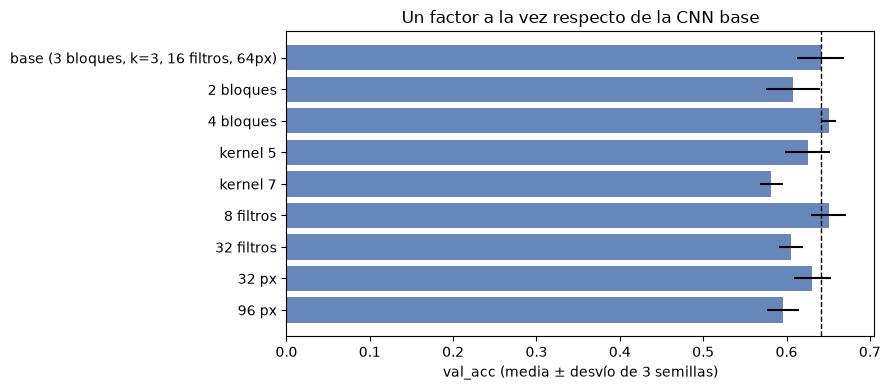

In [19]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

In [20]:
ta = tab_arch.set_index("variante"); b0 = ta.iloc[0]; nva = len(idx_va); se_b = se_acc(b0["val_acc"], nva)
rows_a = []
for nm, r_ in ta.iloc[1:].iterrows():
    d = r_["val_acc"] - b0["val_acc"]; u = umbral(b0["val_acc_std"], r_["val_acc_std"], b0["val_acc"], nva)
    rows_a.append(dict(variante=nm, delta_pts=100 * d, umbral_pts=100 * u, veredicto=veredicto(d, b0["val_acc_std"], r_["val_acc_std"], b0["val_acc"], nva),
                       campo_receptivo=int(r_["campo_receptivo"]), params_vs_base=r_["params"] / b0["params"], tiempo_vs_base=r_["t_total_s"] / b0["t_total_s"]))
dfa = pd.DataFrame(rows_a).set_index("variante"); display(dfa.round(3))
sup = dfa[dfa["veredicto"] == "supera el ruido"].index.tolist(); marg = dfa[dfa["veredicto"].str.startswith("supera el umbral")].index.tolist()
head_p = {s_: CNN(s_).head[1].in_features * 128 + 128 for s_ in SIZES}; hin = {s_: CNN(s_).head[1].in_features for s_ in SIZES}
conv_p = {s_: n_params(CNN(s_)) - head_p[s_] - 128 * NUM_CLASSES - NUM_CLASSES for s_ in SIZES}
cnn_b = {b_: n_params(CNN(64, n_blocks=b_)) for b_ in [2, 3, 4]}; hp_b = {b_: CNN(64, n_blocks=b_).head[1].in_features * 128 + 128 for b_ in [2, 3, 4]}
r32, r96 = ta.loc["32 px"], ta.loc["96 px"]
def f_(nm): return f"{nm} {dfa.loc[nm, 'delta_pts']:+.1f} puntos ({dfa.loc[nm, 'veredicto']})"
md(f"""#### Análisis 2 - Arquitectura convolucional (generado a partir de la tabla de arriba)

**1. Qué supera el ruido.** Regla: una diferencia contra la base se considera real si supera el mayor entre el desvío entre semillas de las dos configuraciones y el error estándar binomial de la validación (±{100 * se_b:.1f} puntos con {nva} imágenes). Diferencias contra la base (val_acc {b0['val_acc']:.3f} ± {b0['val_acc_std']:.3f}): {'; '.join(f_(nm) for nm in dfa.index)}. {'Ninguna variante supera claramente el ruido.' if not sup else 'Superan claramente el ruido: ' + ', '.join(sup) + '.'} {('Superan el umbral por un margen chico (menos de 1.5 veces) y no son concluyentes con 3 semillas: ' + ', '.join(marg) + '.') if marg else ''} Cuando una variante aparece "peor" por poco, es compatible con que sea igual a la base; el desvío entre 3 semillas es en sí una estimación muy ruidosa (se calcula con tres números).

**2. Profundidad y kernel.** El campo receptivo teórico de la última convolución va de {int(ta.loc['2 bloques', 'campo_receptivo'])} px (2 bloques) a {int(ta.loc['4 bloques', 'campo_receptivo'])} px (4 bloques) con kernel 3, y de {int(b0['campo_receptivo'])} px (base) a {int(ta.loc['kernel 5', 'campo_receptivo'])} y {int(ta.loc['kernel 7', 'campo_receptivo'])} px con kernel 5 y 7, sobre una imagen de 64 px: de {pct(ta.loc['2 bloques', 'campo_receptivo'] / 64)} a {pct(ta.loc['kernel 7', 'campo_receptivo'] / 64)} del lado. Con un campo receptivo chico cada unidad solo ve bordes y texturas locales (puntos, retículas, vasos); para ver rasgos de forma global de la lesión (asimetría, borde completo, distribución del color) el campo debe acercarse al tamaño de la lesión. Se esperaba que más profundidad o kernels grandes ayudaran; se observó {'que ninguna de las dos cosas supera el ruido' if not any(n in sup for n in ['4 bloques', 'kernel 5', 'kernel 7', '2 bloques']) else 'una diferencia que supera el ruido en alguna de ellas (ver el punto 1)'}: con 4 bloques el val_acc es {ta.loc['4 bloques', 'val_acc']:.3f} contra {b0['val_acc']:.3f}. **Costo:** los parámetros no crecen con la profundidad: 2 bloques tiene {int(ta.loc['2 bloques', 'params']):,} y 4 bloques {int(ta.loc['4 bloques', 'params']):,} (base {int(b0['params']):,}), porque con menos pooling el mapa final es más grande y la `Linear` de la cabeza se agranda (con 2 bloques la cabeza tiene {hp_b[2]:,} parámetros; con 4, {hp_b[4]:,}). Lo que sí crece es el tiempo: el entrenamiento completo tarda {ta.loc['4 bloques', 't_total_s']:.0f} s con 4 bloques contra {b0['t_total_s']:.0f} s con la base; el kernel 7 cuesta {ta.loc['kernel 7', 't_total_s'] / b0['t_total_s']:.1f} veces el tiempo de la base ({ta.loc['kernel 7', 't_epoca_s'] / b0['t_epoca_s']:.1f} veces por época) por {pts(ta.loc['kernel 7', 'val_acc'] - b0['val_acc'])} puntos de val_acc. Los filtros (8, 16 o 32 por bloque) tampoco muestran una mejora clara ({pts(ta.loc['8 filtros', 'val_acc'] - b0['val_acc'])} y {pts(ta.loc['32 filtros', 'val_acc'] - b0['val_acc'])} puntos): 32 filtros multiplican los parámetros por {ta.loc['32 filtros', 'params'] / b0['params']:.1f} y el tiempo por época por {ta.loc['32 filtros', 't_epoca_s'] / b0['t_epoca_s']:.1f}, y 8 filtros lo reducen a {ta.loc['8 filtros', 't_epoca_s'] / b0['t_epoca_s']:.1f} veces con una val_acc {'comparable' if abs(ta.loc['8 filtros', 'val_acc'] - b0['val_acc']) < se_b else 'distinta'}.

**3. Resolución de entrada.** La parte convolucional casi no cambia con la resolución ({conv_p[32]:,}, {conv_p[64]:,} y {conv_p[96]:,} parámetros a 32, 64 y 96 px: son idénticos, los filtros no dependen del tamaño), pero la `Linear` de la cabeza recibe `64·(size/8)²` valores: {hin[32]:,} a 32 px, {hin[64]:,} a 64 y {hin[96]:,} a 96, es decir {head_p[32]:,}, {head_p[64]:,} y {head_p[96]:,} parámetros; el total pasa de {int(r32['params']):,} a {int(b0['params']):,} y {int(r96['params']):,}. A 96 px se dispone de más detalle (textura, retículas), pero cuesta {r96['t_epoca_s'] / b0['t_epoca_s']:.1f} veces el tiempo por época de 64 px y el campo receptivo de {int(b0['campo_receptivo'])} px cubre una fracción menor de la imagen ({pct(b0['campo_receptivo'] / 32)} a 32 px, {pct(b0['campo_receptivo'] / 64)} a 64 px, {pct(b0['campo_receptivo'] / 96)} a 96 px). Resultado: 32 px da val_acc {r32['val_acc']:.3f} ± {r32['val_acc_std']:.3f} contra {b0['val_acc']:.3f} ± {b0['val_acc_std']:.3f} a 64 px y {r96['val_acc']:.3f} ± {r96['val_acc_std']:.3f} a 96 px, con {b0['params'] / r32['params']:.1f} veces menos parámetros y {b0['t_epoca_s'] / r32['t_epoca_s']:.1f} veces menos tiempo por época que 64 px. Una explicación posible (no verificada con un experimento aparte) es que con ~{int(len(idx_tr) / NUM_CLASSES)} imágenes por clase la red no aprovecha el detalle extra, porque más entradas y parámetros le dan más capacidad para memorizar, y bajar la resolución actúa como una regularización. **Límites del experimento:** son solo 3 resoluciones, con los mismos hiperparámetros (lr, épocas, dropout) elegidos para 64 px; las imágenes se achican desde resoluciones originales muy distintas (de 294×222 a 1024×768), de modo que no se puede separar el efecto de la resolución del de la fuente de las imágenes; y la diferencia entre 32 y 64 px {'no supera' if abs(r32['val_acc'] - b0['val_acc']) <= umbral(r32['val_acc_std'], b0['val_acc_std'], b0['val_acc'], nva) else 'supera'} el ruido.

**4. Qué no se puede concluir.** Con "un factor a la vez" y 3 semillas: (a) no se ven interacciones (por ejemplo, 4 bloques con 32 filtros, o kernel 7 con 96 px), (b) los demás hiperparámetros quedan fijos en los valores de la base, (c) el desvío de 3 semillas es poco confiable, (d) todas las comparaciones usan la misma partición y la misma validación de {nva} imágenes, que además se usa para el early stopping (se reporta la val_acc de la época de menor val_loss, por lo que los números son algo optimistas) y para elegir la configuración final, y (e) diferencias de 1–3 puntos no se pueden distinguir del azar con este tamaño de validación.""")

,delta_pts,umbral_pts,veredicto,campo_receptivo,params_vs_base,tiempo_vs_base
variante,,,,,,
2 bloques,-3.353,3.69,dentro del ruido,8,1.921,0.839
4 bloques,0.986,3.69,dentro del ruido,38,0.657,1.208
kernel 5,-1.578,3.69,dentro del ruido,32,1.076,1.359
kernel 7,-5.917,3.69,supera el ruido,46,1.190,2.047
8 filtros,0.986,3.69,dentro del ruido,18,0.491,0.389
32 filtros,-3.550,3.69,dentro del ruido,18,2.082,2.498
32 px,-0.986,3.69,dentro del ruido,18,0.284,0.230
96 px,-4.536,3.69,supera el umbral por poco (no concluyente con ...,18,2.193,2.599


#### Análisis 2 - Arquitectura convolucional (generado a partir de la tabla de arriba)

**1. Qué supera el ruido.** Regla: una diferencia contra la base se considera real si supera el mayor entre el desvío entre semillas de las dos configuraciones y el error estándar binomial de la validación (±3.7 puntos con 169 imágenes). Diferencias contra la base (val_acc 0.641 ± 0.028): 2 bloques -3.4 puntos (dentro del ruido); 4 bloques +1.0 puntos (dentro del ruido); kernel 5 -1.6 puntos (dentro del ruido); kernel 7 -5.9 puntos (supera el ruido); 8 filtros +1.0 puntos (dentro del ruido); 32 filtros -3.6 puntos (dentro del ruido); 32 px -1.0 puntos (dentro del ruido); 96 px -4.5 puntos (supera el umbral por poco (no concluyente con 3 semillas)). Superan claramente el ruido: kernel 7. Superan el umbral por un margen chico (menos de 1.5 veces) y no son concluyentes con 3 semillas: 96 px. Cuando una variante aparece "peor" por poco, es compatible con que sea igual a la base; el desvío entre 3 semillas es en sí una estimación muy ruidosa (se calcula con tres números).

**2. Profundidad y kernel.** El campo receptivo teórico de la última convolución va de 8 px (2 bloques) a 38 px (4 bloques) con kernel 3, y de 18 px (base) a 32 y 46 px con kernel 5 y 7, sobre una imagen de 64 px: de 12 % a 72 % del lado. Con un campo receptivo chico cada unidad solo ve bordes y texturas locales (puntos, retículas, vasos); para ver rasgos de forma global de la lesión (asimetría, borde completo, distribución del color) el campo debe acercarse al tamaño de la lesión. Se esperaba que más profundidad o kernels grandes ayudaran; se observó una diferencia que supera el ruido en alguna de ellas (ver el punto 1): con 4 bloques el val_acc es 0.651 contra 0.641. **Costo:** los parámetros no crecen con la profundidad: 2 bloques tiene 1,055,001 y 4 bloques 361,113 (base 549,273), porque con menos pooling el mapa final es más grande y la `Linear` de la cabeza se agranda (con 2 bloques la cabeza tiene 1,048,704 parámetros; con 4, 262,272). Lo que sí crece es el tiempo: el entrenamiento completo tarda 42 s con 4 bloques contra 35 s con la base; el kernel 7 cuesta 2.0 veces el tiempo de la base (1.7 veces por época) por -5.9 puntos de val_acc. Los filtros (8, 16 o 32 por bloque) tampoco muestran una mejora clara (+1.0 y -3.6 puntos): 32 filtros multiplican los parámetros por 2.1 y el tiempo por época por 2.1, y 8 filtros lo reducen a 0.4 veces con una val_acc comparable.

**3. Resolución de entrada.** La parte convolucional casi no cambia con la resolución (23,696, 23,696 y 23,696 parámetros a 32, 64 y 96 px: son idénticos, los filtros no dependen del tamaño), pero la `Linear` de la cabeza recibe `64·(size/8)²` valores: 1,024 a 32 px, 4,096 a 64 y 9,216 a 96, es decir 131,200, 524,416 y 1,179,776 parámetros; el total pasa de 156,057 a 549,273 y 1,204,633. A 96 px se dispone de más detalle (textura, retículas), pero cuesta 2.2 veces el tiempo por época de 64 px y el campo receptivo de 18 px cubre una fracción menor de la imagen (56 % a 32 px, 28 % a 64 px, 19 % a 96 px). Resultado: 32 px da val_acc 0.631 ± 0.022 contra 0.641 ± 0.028 a 64 px y 0.596 ± 0.020 a 96 px, con 3.5 veces menos parámetros y 3.8 veces menos tiempo por época que 64 px. Una explicación posible (no verificada con un experimento aparte) es que con ~56 imágenes por clase la red no aprovecha el detalle extra, porque más entradas y parámetros le dan más capacidad para memorizar, y bajar la resolución actúa como una regularización. **Límites del experimento:** son solo 3 resoluciones, con los mismos hiperparámetros (lr, épocas, dropout) elegidos para 64 px; las imágenes se achican desde resoluciones originales muy distintas (de 294×222 a 1024×768), de modo que no se puede separar el efecto de la resolución del de la fuente de las imágenes; y la diferencia entre 32 y 64 px no supera el ruido.

**4. Qué no se puede concluir.** Con "un factor a la vez" y 3 semillas: (a) no se ven interacciones (por ejemplo, 4 bloques con 32 filtros, o kernel 7 con 96 px), (b) los demás hiperparámetros quedan fijos en los valores de la base, (c) el desvío de 3 semillas es poco confiable, (d) todas las comparaciones usan la misma partición y la misma validación de 169 imágenes, que además se usa para el early stopping (se reporta la val_acc de la época de menor val_loss, por lo que los números son algo optimistas) y para elegir la configuración final, y (e) diferencias de 1–3 puntos no se pueden distinguir del azar con este tamaño de validación.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6410,0.0283,0.7708,0.1297,1.0473,11.6667,1.4342,31.0514
1,flips,1518,0.6331,0.0174,0.8136,0.1804,1.0382,8.6667,4.8391,91.0162
2,flips+rot90,1518,0.6647,0.0223,0.8399,0.1752,1.0134,11.3333,4.8822,104.3605
3,flips+rot90+color,1518,0.6233,0.0275,0.7819,0.1587,1.0369,10.6667,5.0000,102.1920


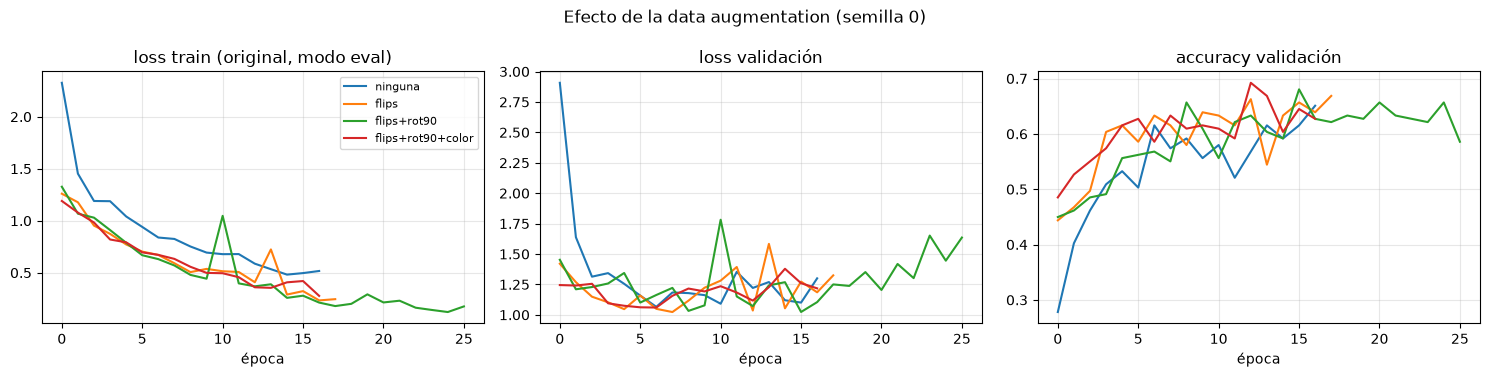

In [21]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

In [22]:
tg = tab_aug.set_index("augmentation"); g0 = tg.loc["ninguna"]; nva = len(idx_va); h0 = aug_hist["ninguna"]
be = h0["best_epoch"] - 1; n_ep = h0["n_epochs"]
vl_min, vl_last = min(h0["val_loss"]), h0["val_loss"][-1]; tl_best, tl_last = h0["train_loss"][be], h0["train_loss"][-1]
tra_last, va_last = h0["train_acc"][-1], h0["val_acc"][-1]
rows_g = []
for nm, r_ in tg.iloc[1:].iterrows():
    d = r_["val_acc"] - g0["val_acc"]; u = umbral(g0["val_acc_std"], r_["val_acc_std"], g0["val_acc"], nva)
    rows_g.append(dict(augmentation=nm, delta_val_acc_pts=100 * d, umbral_pts=100 * u, veredicto=veredicto(d, g0["val_acc_std"], r_["val_acc_std"], g0["val_acc"], nva),
                       delta_brecha_pts=100 * (r_["brecha"] - g0["brecha"]), delta_val_loss=r_["val_loss"] - g0["val_loss"], mejor_epoca=r_["best_epoch"],
                       tiempo_epoca_vs_sin=r_["t_epoca_s"] / g0["t_epoca_s"], tiempo_total_vs_sin=r_["t_total_s"] / g0["t_total_s"]))
dg = pd.DataFrame(rows_g).set_index("augmentation"); display(dg.round(3))
sup_g = dg[dg["veredicto"] == "supera el ruido"].index.tolist()
mejor_vl = dg["delta_val_loss"].idxmin(); mejor_va = dg["delta_val_acc_pts"].idxmax(); menor_br = dg["delta_brecha_pts"].idxmin()
res_aug = ("Resultado contrario a lo esperado: **la augmentation no mejoró la validación más allá del ruido**. Posibles razones, que no se verificaron con experimentos aparte: (a) las copias son fijas (dos por imagen) y no transformaciones nuevas en cada época, lo que limita la diversidad real; (b) con " + str(len(idx_va)) + " imágenes de validación no se detectan mejoras de 1–2 puntos; (c) los flips y rotaciones de 90° no actúan sobre lo que puede estar sesgado en el dataset (resolución/fuente y color medio, ver EDA), y el early stopping ya corta antes del peor sobreajuste."
           if not sup_g else "La augmentation mejora la validación más allá del ruido en: " + ", ".join(n for n in sup_g if dg.loc[n, "delta_val_acc_pts"] > 0) + " (ver el punto anterior para las que empeoran).")
md(f"""#### Análisis 3 - Overfitting y data augmentation (generado a partir de las tablas y curvas de arriba)

**1. Overfitting sin augmentation, con números.** La CNN base sin augmentation tiene en promedio de 3 semillas una accuracy de train de {pct(g0['train_acc'], 1)} contra {pct(g0['val_acc'], 1)} en validación: una **brecha de {100 * g0['brecha']:.1f} puntos** (la val_acc es la de la época de menor val_loss). En la semilla 0 de las curvas, la val_loss alcanza su mínimo ({vl_min:.3f}) en la época {h0['best_epoch']}; las {n_ep - h0['best_epoch']} épocas siguientes (hasta el corte por paciencia, época {n_ep}) la val_loss {'sube' if vl_last > vl_min else 'no sube'} a {vl_last:.3f} ({(vl_last / vl_min - 1) * 100:+.0f} %) mientras la loss de train {'baja' if tl_last < tl_best else 'no baja'} de {tl_best:.3f} a {tl_last:.3f} y la accuracy de train llega a {pct(tra_last, 0)} con {pct(va_last, 0)} en validación. La red sigue aprendiendo los ejemplos de train pero ya no generaliza: sobreajuste clásico (y el early stopping por val_loss es lo que evita que el número reportado sea peor).

**2. Efecto de cada nivel** (contra "ninguna"; la val_acc, la brecha y la val_loss son medias de 3 semillas): {'; '.join(f"**{nm}**: val_acc {r_['delta_val_acc_pts']:+.1f} puntos ({r_['veredicto']}), brecha {r_['delta_brecha_pts']:+.1f} puntos, val_loss {r_['delta_val_loss']:+.3f}, mejor época {r_['mejor_epoca']:.0f} (sin aug: {g0['best_epoch']:.0f}), tiempo por época ×{r_['tiempo_epoca_vs_sin']:.1f} y total ×{r_['tiempo_total_vs_sin']:.1f}" for nm, r_ in dg.iterrows())}. {'Ninguna mejora de val_acc supera el ruido entre semillas ni el error estándar de la validación (±' + f'{100 * se_acc(g0["val_acc"], nva):.1f}' + ' puntos).' if not sup_g else 'Superan el ruido: ' + ', '.join(sup_g) + '.'} La mayor reducción de la val_loss es la de **{mejor_vl}** ({dg.loc[mejor_vl, 'delta_val_loss']:+.3f}), la mejor val_acc relativa a la base la de **{mejor_va}** ({dg.loc[mejor_va, 'delta_val_acc_pts']:+.1f} puntos, es decir, {'una mejora' if dg.loc[mejor_va, 'delta_val_acc_pts'] > 0 else 'ninguna mejora'} respecto de no aumentar) y la menor brecha la de **{menor_br}** ({dg.loc[menor_br, 'delta_brecha_pts']:+.1f} puntos). Cada época cuesta más porque el conjunto de train pasa de {int(tg.loc['ninguna', 'n_train'])} a {int(tg.loc['flips', 'n_train'])} imágenes (originales + {AUG_COPIES} copias de cada una), así que hay {tg.loc['flips', 'n_train'] / tg.loc['ninguna', 'n_train']:.1f} veces más pasos por época; el tiempo por época sube ×{dg['tiempo_epoca_vs_sin'].mean():.1f} en promedio, coherente con eso (las copias se generan una sola vez, antes de entrenar). {res_aug}

**3. Desde el dominio (dermatología).** Tienen sentido las transformaciones que no cambian el diagnóstico: las imágenes dermatoscópicas **no tienen orientación canónica** (la lesión se fotografía desde cualquier ángulo), así que flips y rotaciones de 90° generan imágenes plausibles; también variaciones leves de brillo/contraste, que imitan diferencias de iluminación y de equipo. Pueden **destruir información**: cambios de tono/saturación (el color de la lesión es parte del diagnóstico: pigmento marrón/negro/azulado en melanomas, rojo en lesiones vasculares), recortes o zoom fuertes (el **tamaño** y el borde completo de la lesión son criterios clínicos: un recorte puede dejar la lesión fuera o cambiar su escala aparente) y deformaciones elásticas que alteren la irregularidad del borde. Otras a probar: rotaciones por cualquier ángulo con relleno por reflexión, recortes aleatorios suaves, corrección de color (*color constancy*, p. ej. *Shades of Gray*) para reducir el sesgo de la fuente, simulación de pelos u oclusiones (*cutout*), y Mixup/CutMix.

**4. Después del split y solo en train.** Si se aumentara antes de dividir, copias transformadas de una misma imagen caerían en train y en validación/test: la red vería en train la imagen casi idéntica a la que se evalúa (un flip es la misma lesión), la val_acc medida sería memorización y no generalización, igual que con los duplicados exactos; todas las decisiones (early stopping, elección de arquitectura) se tomarían sobre una métrica inflada. Val y test deben reflejar imágenes reales, no sintéticas, y no deben tocarse. En la sección 9.1 se cuantifica este efecto con un experimento.

**5. Comparación con el TP3.** Dropout, L1/L2 y BatchNorm **restringen o perturban el modelo** (achican los pesos, apagan neuronas, normalizan activaciones): reducen la capacidad efectiva sin agregar información. La augmentation **agrega información del dominio** (invariancias que sabemos ciertas: la lesión sigue siendo la misma al rotarla) y aumenta el tamaño efectivo del conjunto de entrenamiento. Se parecen en que apuntan a reducir la brecha train-val y se combinan; se diferencian en que la augmentation requiere conocimiento del dominio (una transformación inválida mete ruido de etiquetas) y cuesta cómputo en cada época, mientras que la regularización de pesos no necesita conocer el problema. En el TP3 tampoco encontramos que la regularización explícita redujera la brecha sin perder accuracy; acá la augmentation tampoco la redujo de forma clara: en ambos casos la limitación parece estar más en la cantidad y variedad de datos que en la capacidad del modelo.""")

,delta_val_acc_pts,umbral_pts,veredicto,delta_brecha_pts,delta_val_loss,mejor_epoca,tiempo_epoca_vs_sin,tiempo_total_vs_sin
augmentation,,,,,,,,
flips,-0.789,3.69,dentro del ruido,5.071,-0.009,8.667,3.374,2.931
flips+rot90,2.367,3.69,dentro del ruido,4.550,-0.034,11.333,3.404,3.361
flips+rot90+color,-1.775,3.69,dentro del ruido,2.895,-0.010,10.667,3.486,3.291


#### Análisis 3 - Overfitting y data augmentation (generado a partir de las tablas y curvas de arriba)

**1. Overfitting sin augmentation, con números.** La CNN base sin augmentation tiene en promedio de 3 semillas una accuracy de train de 77.1 % contra 64.1 % en validación: una **brecha de 13.0 puntos** (la val_acc es la de la época de menor val_loss). En la semilla 0 de las curvas, la val_loss alcanza su mínimo (1.066) en la época 7; las 10 épocas siguientes (hasta el corte por paciencia, época 17) la val_loss sube a 1.300 (+22 %) mientras la loss de train baja de 0.839 a 0.517 y la accuracy de train llega a 80 % con 65 % en validación. La red sigue aprendiendo los ejemplos de train pero ya no generaliza: sobreajuste clásico (y el early stopping por val_loss es lo que evita que el número reportado sea peor).

**2. Efecto de cada nivel** (contra "ninguna"; la val_acc, la brecha y la val_loss son medias de 3 semillas): **flips**: val_acc -0.8 puntos (dentro del ruido), brecha +5.1 puntos, val_loss -0.009, mejor época 9 (sin aug: 12), tiempo por época ×3.4 y total ×2.9; **flips+rot90**: val_acc +2.4 puntos (dentro del ruido), brecha +4.6 puntos, val_loss -0.034, mejor época 11 (sin aug: 12), tiempo por época ×3.4 y total ×3.4; **flips+rot90+color**: val_acc -1.8 puntos (dentro del ruido), brecha +2.9 puntos, val_loss -0.010, mejor época 11 (sin aug: 12), tiempo por época ×3.5 y total ×3.3. Ninguna mejora de val_acc supera el ruido entre semillas ni el error estándar de la validación (±3.7 puntos). La mayor reducción de la val_loss es la de **flips+rot90** (-0.034), la mejor val_acc relativa a la base la de **flips+rot90** (+2.4 puntos, es decir, una mejora respecto de no aumentar) y la menor brecha la de **flips+rot90+color** (+2.9 puntos). Cada época cuesta más porque el conjunto de train pasa de 506 a 1518 imágenes (originales + 2 copias de cada una), así que hay 3.0 veces más pasos por época; el tiempo por época sube ×3.4 en promedio, coherente con eso (las copias se generan una sola vez, antes de entrenar). Resultado contrario a lo esperado: **la augmentation no mejoró la validación más allá del ruido**. Posibles razones, que no se verificaron con experimentos aparte: (a) las copias son fijas (dos por imagen) y no transformaciones nuevas en cada época, lo que limita la diversidad real; (b) con 169 imágenes de validación no se detectan mejoras de 1–2 puntos; (c) los flips y rotaciones de 90° no actúan sobre lo que puede estar sesgado en el dataset (resolución/fuente y color medio, ver EDA), y el early stopping ya corta antes del peor sobreajuste.

**3. Desde el dominio (dermatología).** Tienen sentido las transformaciones que no cambian el diagnóstico: las imágenes dermatoscópicas **no tienen orientación canónica** (la lesión se fotografía desde cualquier ángulo), así que flips y rotaciones de 90° generan imágenes plausibles; también variaciones leves de brillo/contraste, que imitan diferencias de iluminación y de equipo. Pueden **destruir información**: cambios de tono/saturación (el color de la lesión es parte del diagnóstico: pigmento marrón/negro/azulado en melanomas, rojo en lesiones vasculares), recortes o zoom fuertes (el **tamaño** y el borde completo de la lesión son criterios clínicos: un recorte puede dejar la lesión fuera o cambiar su escala aparente) y deformaciones elásticas que alteren la irregularidad del borde. Otras a probar: rotaciones por cualquier ángulo con relleno por reflexión, recortes aleatorios suaves, corrección de color (*color constancy*, p. ej. *Shades of Gray*) para reducir el sesgo de la fuente, simulación de pelos u oclusiones (*cutout*), y Mixup/CutMix.

**4. Después del split y solo en train.** Si se aumentara antes de dividir, copias transformadas de una misma imagen caerían en train y en validación/test: la red vería en train la imagen casi idéntica a la que se evalúa (un flip es la misma lesión), la val_acc medida sería memorización y no generalización, igual que con los duplicados exactos; todas las decisiones (early stopping, elección de arquitectura) se tomarían sobre una métrica inflada. Val y test deben reflejar imágenes reales, no sintéticas, y no deben tocarse. En la sección 9.1 se cuantifica este efecto con un experimento.

**5. Comparación con el TP3.** Dropout, L1/L2 y BatchNorm **restringen o perturban el modelo** (achican los pesos, apagan neuronas, normalizan activaciones): reducen la capacidad efectiva sin agregar información. La augmentation **agrega información del dominio** (invariancias que sabemos ciertas: la lesión sigue siendo la misma al rotarla) y aumenta el tamaño efectivo del conjunto de entrenamiento. Se parecen en que apuntan a reducir la brecha train-val y se combinan; se diferencian en que la augmentation requiere conocimiento del dominio (una transformación inválida mete ruido de etiquetas) y cuesta cómputo en cada época, mientras que la regularización de pesos no necesita conocer el problema. En el TP3 tampoco encontramos que la regularización explícita redujera la brecha sin perder accuracy; acá la augmentation tampoco la redujo de forma clara: en ambos casos la limitación parece estar más en la cantidad y variedad de datos que en la capacidad del modelo.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [23]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 8 filtros | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 3, 'filters': 8, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.619 ± 0.003 | brecha 0.197 | mejor época 6.7 | 29s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,269521,0.6615,0.0121,0.6567,0.0154,30.1252
1,MLP 64px,6358793,0.4982,0.0422,0.4708,0.0458,17.6533


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.53      0.45      0.49        20
         Atopic Dermatitis       0.78      0.88      0.82        16
          Benign keratosis       0.94      0.85      0.89        20
            Dermatofibroma       0.47      0.70      0.56        20
         Melanocytic nevus       0.68      0.65      0.67        20
                  Melanoma       0.52      0.65      0.58        20
   Squamous cell carcinoma       0.58      0.55      0.56        20
Tinea Ringworm Candidiasis       0.80      0.31      0.44        13
           Vascular lesion       1.00      0.90      0.95        20

                  accuracy                           0.67       169
                 macro avg       0.70      0.66      0.66       169
              weighted avg       0.69      0.67      0.67       169



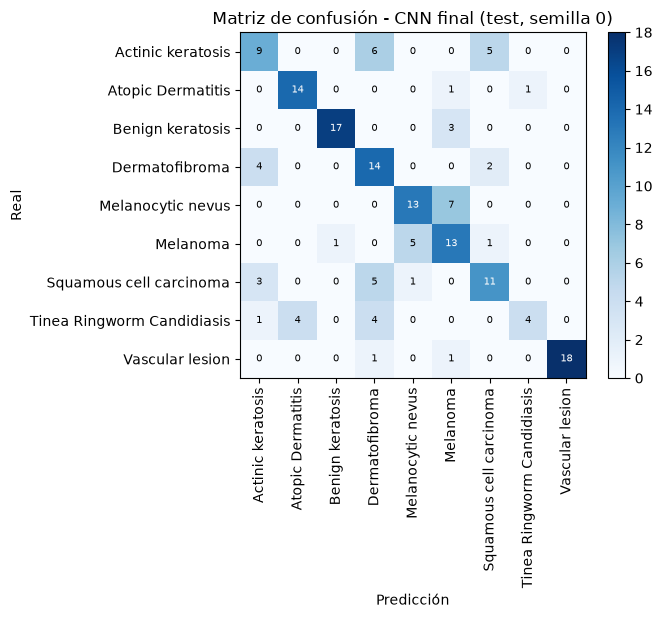

In [24]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

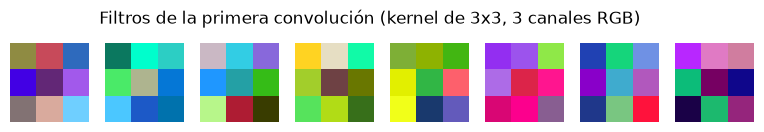

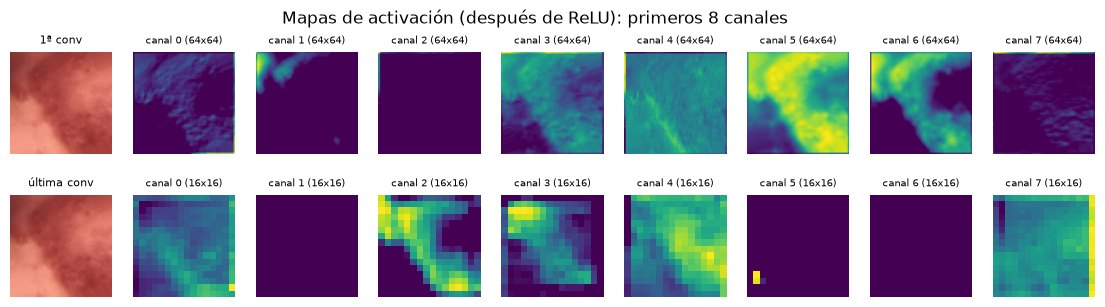

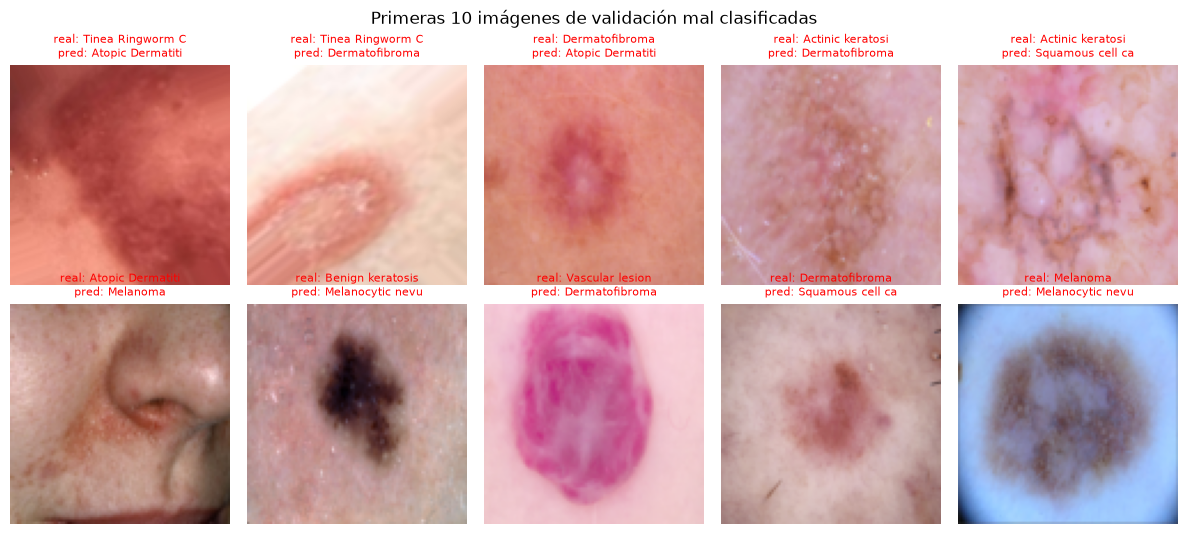

In [25]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### 9.1 Controles de sesgo y fuga (solo train y val; el test no se toca)
Antes del análisis final se miden tres cosas que el EDA y el análisis 3 plantean pero que el notebook base no cuantifica: cuánto predicen la clase **solo la resolución original o solo el color medio**, qué le pasa a la `val_acc` si se **entrena con la partición original (con duplicados)** y qué pasa si se **aumenta antes de dividir**.

In [26]:
# ---- 9.1 Controles adicionales sobre sesgos y fugas (usan SOLO train/val, nunca test) ----
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

def fit_generic(Xtr_u8, Ytr_, Xva_u8, Yva_, cfg, seed):
    # mismo entrenamiento que fit() (Adam, early stopping por val_loss, misma paciencia), pero con tensores explícitos
    set_seed(seed); size = cfg["size"]; model = make_model(cfg).to(device); opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    best, bad, best_pred = 1e9, 0, None
    for ep in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr_u8))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr_u8[ids], size)), Ytr_[ids].to(device)).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            out = torch.cat([model(norm_batch(Xva_u8[i:i + 256], size)) for i in range(0, len(Xva_u8), 256)])
            vl = F.cross_entropy(out, Yva_.to(device)).item(); pred = out.argmax(1).cpu()
        if vl < best - 1e-4: best, bad, best_pred = vl, 0, pred
        else:
            bad += 1
            if bad >= PATIENCE: break
    return best_pred

# (a) ¿cuánto predicen la clase solo la resolución o solo el color medio? (mismo split sin duplicados; se evalúa en val)
wh = df[["w", "h"]].values.astype(float); col = mean_rgb[["R", "G", "B"]].values
res_tree = DecisionTreeClassifier(max_depth=4, random_state=0).fit(wh[idx_tr], labels[idx_tr]); acc_res = accuracy_score(labels[idx_va], res_tree.predict(wh[idx_va]))
col_lr = LogisticRegression(max_iter=2000).fit((col[idx_tr] - col[idx_tr].mean(0)) / col[idx_tr].std(0), labels[idx_tr])
acc_col = accuracy_score(labels[idx_va], col_lr.predict((col[idx_va] - col[idx_tr].mean(0)) / col[idx_tr].std(0)))
maj = np.bincount(labels[idx_tr]).argmax(); acc_maj = accuracy_score(labels[idx_va], np.full(len(idx_va), maj))
# (b) duplicados: entrenar con la partición ORIGINAL (con copias de val en train) y medir dónde acierta
orig_tr = df.index[df["carpeta"] == "train"].values; orig_va = df.index[df["carpeta"] == "val"].values
leak = df.loc[orig_va, "md5"].isin(set(df.loc[orig_tr, "md5"])).values
accs_all, accs_dup, accs_nodup = [], [], []
for s in SEEDS:
    p_ = fit_generic(X_U8[64][orig_tr], Y[orig_tr], X_U8[64][orig_va], Y[orig_va], BASE, s).numpy(); ok = (p_ == labels[orig_va])
    accs_all.append(ok.mean()); accs_dup.append(ok[leak].mean()); accs_nodup.append(ok[~leak].mean())
# (c) augmentation ANTES del split: copias con flips de las imágenes sin duplicados, y split aleatorio estratificado de la mezcla
keep_ = df.groupby("md5").head(1).index.values; x0 = X_U8[64][keep_]; y0 = Y[keep_]; set_seed(777)
xa = torch.cat([x0] + [(augment(x0.float() / 255, AUGS["flips"]) * 255).round().to(torch.uint8) for _ in range(AUG_COPIES)]); ya = torch.cat([y0] * (1 + AUG_COPIES))
src_id = np.tile(np.arange(len(keep_)), 1 + AUG_COPIES)
i_tr, i_va = train_test_split(np.arange(len(xa)), test_size=0.25, stratify=ya.numpy(), random_state=SEED_SPLIT)
frac_src = np.isin(src_id[i_va], src_id[i_tr]).mean()
accs_pre = [(fit_generic(xa[i_tr], ya[i_tr], xa[i_va], ya[i_va], BASE, s).numpy() == ya[i_va].numpy()).mean() for s in SEEDS]
ref_acc = float(tab_aug.set_index("augmentation").loc["flips", "val_acc"]); ref_std = float(tab_aug.set_index("augmentation").loc["flips", "val_acc_std"])
ctl = pd.DataFrame([
    dict(control="azar (1/9)", val_acc=1 / NUM_CLASSES, std=np.nan),
    dict(control="clase mayoritaria", val_acc=acc_maj, std=np.nan),
    dict(control="solo resolución (w, h) - árbol prof. 4", val_acc=acc_res, std=np.nan),
    dict(control="solo color medio (R, G, B) - regresión logística", val_acc=acc_col, std=np.nan),
    dict(control="CNN base (pipeline correcto, 64 px)", val_acc=float(tab_arch.iloc[0]["val_acc"]), std=float(tab_arch.iloc[0]["val_acc_std"])),
    dict(control="CNN con split ORIGINAL (duplicados train/val)", val_acc=np.mean(accs_all), std=np.std(accs_all)),
    dict(control="   … solo sobre las imágenes de val con copia en train", val_acc=np.mean(accs_dup), std=np.std(accs_dup)),
    dict(control="   … solo sobre las imágenes de val sin copia en train", val_acc=np.mean(accs_nodup), std=np.std(accs_nodup)),
    dict(control="CNN con augmentation ANTES del split (flips)", val_acc=np.mean(accs_pre), std=np.std(accs_pre))]).set_index("control")
display(ctl.round(3))
md(f"""**Qué muestran estos controles** (todos sobre validación, el test no se toca):
- **Fuentes de sesgo del EDA.** Con solo el ancho y el alto de la imagen original un árbol de decisión de profundidad 4 acierta {pct(acc_res, 1)} de la validación; con solo el color medio RGB, una regresión logística {pct(acc_col, 1)}; el azar es {pct(1 / NUM_CLASSES, 1)} y siempre predecir la clase mayoritaria {pct(acc_maj, 1)} (error estándar de la validación: ±{100 * se_acc(0.5, len(idx_va)):.1f} puntos). La CNN base llega a {pct(float(tab_arch.iloc[0]['val_acc']), 1)}. {'Los metadatos de adquisición por sí solos ya recuperan una parte considerable de la señal, de modo que parte del accuracy de las redes puede venir de la fuente y no de la lesión.' if max(acc_res, acc_col) > 0.3 else 'Los metadatos por sí solos predicen poco más que el azar.'} Esto no prueba que la CNN use ese atajo, pero impide atribuirle todo su accuracy a la morfología.
- **Duplicados.** Entrenando con la partición original (con copias exactas de {int(leak.sum())} imágenes de val en train), la val_acc es {pct(np.mean(accs_all), 1)} ± {100 * np.std(accs_all):.1f}: {pct(np.mean(accs_dup), 1)} sobre las imágenes que están también en train (memorización) y {pct(np.mean(accs_nodup), 1)} sobre las que no. La val_acc con el pipeline correcto es {pct(float(tab_arch.iloc[0]['val_acc']), 1)}. Los duplicados {'inflan' if np.mean(accs_all) > float(tab_arch.iloc[0]['val_acc']) else 'no inflan en este caso'} la métrica y {'lo hacen por una vía clara: las imágenes con copia en train se aciertan mucho más que las demás' if np.mean(accs_dup) > np.mean(accs_nodup) + 0.1 else 'sin una diferencia clara entre copias y no copias'} (las dos validaciones tienen conjuntos de imágenes distintos, así que la comparación es orientativa).
- **Augmentation antes del split.** Si se generan {AUG_COPIES} copias con flips de cada imagen y recién después se divide al azar, {pct(frac_src, 0)} de las imágenes de validación tienen en train la imagen original o una copia volteada de ella, y la val_acc sube a {pct(np.mean(accs_pre), 1)} ± {100 * np.std(accs_pre):.1f}, contra {pct(float(tab_arch.iloc[0]['val_acc']), 1)} del pipeline correcto: es una fuga de información, no una mejora del modelo (con augmentation correcta, solo en train: {pct(ref_acc, 1)} ± {100 * ref_std:.1f}).""")

,val_acc,std
control,,
azar (1/9),0.111,NaN
clase mayoritaria,0.118,NaN
"solo resolución (w, h) - árbol prof. 4",0.550,NaN
"solo color medio (R, G, B) - regresión logística",0.320,NaN
"CNN base (pipeline correcto, 64 px)",0.641,0.028
CNN con split ORIGINAL (duplicados train/val),0.650,0.041
… solo sobre las imágenes de val con copia en train,0.859,0.052
… solo sobre las imágenes de val sin copia en train,0.604,0.039
CNN con augmentation ANTES del split (flips),0.811,0.030


**Qué muestran estos controles** (todos sobre validación, el test no se toca):
- **Fuentes de sesgo del EDA.** Con solo el ancho y el alto de la imagen original un árbol de decisión de profundidad 4 acierta 55.0 % de la validación; con solo el color medio RGB, una regresión logística 32.0 %; el azar es 11.1 % y siempre predecir la clase mayoritaria 11.8 % (error estándar de la validación: ±3.8 puntos). La CNN base llega a 64.1 %. Los metadatos de adquisición por sí solos ya recuperan una parte considerable de la señal, de modo que parte del accuracy de las redes puede venir de la fuente y no de la lesión. Esto no prueba que la CNN use ese atajo, pero impide atribuirle todo su accuracy a la morfología.
- **Duplicados.** Entrenando con la partición original (con copias exactas de 33 imágenes de val en train), la val_acc es 65.0 % ± 4.1: 85.9 % sobre las imágenes que están también en train (memorización) y 60.4 % sobre las que no. La val_acc con el pipeline correcto es 64.1 %. Los duplicados inflan la métrica y lo hacen por una vía clara: las imágenes con copia en train se aciertan mucho más que las demás (las dos validaciones tienen conjuntos de imágenes distintos, así que la comparación es orientativa).
- **Augmentation antes del split.** Si se generan 2 copias con flips de cada imagen y recién después se divide al azar, 91 % de las imágenes de validación tienen en train la imagen original o una copia volteada de ella, y la val_acc sube a 81.1 % ± 3.0, contra 64.1 % del pipeline correcto: es una fuga de información, no una mejora del modelo (con augmentation correcta, solo en train: 63.3 % ± 1.7).

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

In [27]:
cr = classification_report(labels[idx_te], final_preds["CNN final"], target_names=class_names, zero_division=0, output_dict=True)
fc, fm = final.loc[0], final.loc[1]; nte = len(idx_te); se_te = se_acc(fc["test_acc"], nte)
d_val = fc["test_acc"] - rf_["val_acc"]; d_cm = fc["test_acc"] - fm["test_acc"]; u_cm = umbral(fc["test_acc_std"], fm["test_acc_std"], fc["test_acc"], nte)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0); order = np.dstack(np.unravel_index(np.argsort(-cm_off.ravel()), cm_off.shape))[0][:4]
conf_txt = "; ".join(f"*{class_names[i]}* → *{class_names[j]}* ({cm[i, j]} de {cm[i].sum()})" for i, j in order)
mel = class_names.index("Melanoma"); scc = class_names.index("Squamous cell carcinoma"); mal = [mel, scc]
rec_mel = cm[mel, mel] / cm[mel].sum(); mel_como = {class_names[j]: int(cm[mel, j]) for j in range(NUM_CLASSES) if j != mel and cm[mel, j] > 0}
mel_benigno = sum(int(cm[mel, class_names.index(c)]) for c in ["Melanocytic nevus", "Benign keratosis"])
sens_mal = cm[np.ix_(mal, mal)].sum() / cm[mal].sum()
f1c = {c: cr[c]["f1-score"] for c in class_names}; rc = {c: cr[c]["recall"] for c in class_names}
peor_f1 = sorted(f1c, key=f1c.get)[:3]; mejor_f1 = sorted(f1c, key=f1c.get)[-2:]
# errores de validación (todos), contraste y clases
_, _, pv_all = evaluate(model, idx_va, size); err = pv_all != labels[idx_va]
gray_v = X_U8[size][idx_va].float().mean(1); contr = gray_v.flatten(1).std(1).numpy(); bril = gray_v.flatten(1).mean(1).numpy()
err_cls = pd.Series(np.array(class_names)[labels[idx_va][err]]).value_counts()
pares_val = pd.Series([f"{class_names[a]} → {class_names[b]}" for a, b in zip(labels[idx_va][err], pv_all[err])]).value_counts().head(3)
dead_first = int((a_first.flatten(1).max(1).values < 1e-6).sum()); dead_last = int((a_last.flatten(1).max(1).values < 1e-6).sum())
W1 = model.features[0].weight.detach().cpu(); k1 = W1.shape[2]
md(f"""#### Análisis 4 - Resultados finales e interpretación (generado a partir de los outputs de las secciones 8 y 9)

**1. Val vs. test.** Configuración final: {best_arch} con augmentation "{best_aug}" (elegida por mejor val_acc media). En validación: {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} (3 semillas); en test: {fc['test_acc']:.3f} ± {fc['test_acc_std']:.3f} (5 semillas, {nte} imágenes). La diferencia es de {pts(d_val)} puntos, contra un error estándar binomial del test de ±{100 * se_te:.1f} puntos: {'es coherente (dentro del error)' if abs(d_val) < se_te else 'excede el error estándar'}. Dos matices: (i) la configuración se eligió entre {len(tab_arch)} variantes de arquitectura y {len(tab_aug)} de augmentation por su desempeño en validación, y la época de cada entrenamiento también se eligió con la val_loss: eso sesga la validación hacia arriba, de modo que el test (que no participó de ninguna decisión) es la estimación honesta; (ii) {'la configuración elegida no se distingue de la base dentro del ruido (ver análisis 2), así que la elección entre ellas fue en buena medida azar y el test no confirma que esa variante sea mejor.' if best_arch != tab_arch.iloc[0]['variante'] and tab_arch.set_index('variante').loc[best_arch, 'val_acc'] - tab_arch.iloc[0]['val_acc'] <= umbral(tab_arch.set_index('variante').loc[best_arch, 'val_acc_std'], tab_arch.iloc[0]['val_acc_std'], tab_arch.iloc[0]['val_acc'], len(idx_va)) else 'la configuración elegida se distingue de la base.'}

**2. CNN vs. MLP en test.** CNN final {fc['test_acc']:.3f} ± {fc['test_acc_std']:.3f} (F1 macro {fc['test_f1_macro']:.3f}) contra MLP 64 px {fm['test_acc']:.3f} ± {fm['test_acc_std']:.3f} (F1 macro {fm['test_f1_macro']:.3f}): {pts(d_cm)} puntos; el umbral (mayor entre los desvíos entre semillas y el error estándar del test) es {100 * u_cm:.1f} puntos, así que la diferencia {'supera el ruido' if abs(d_cm) > u_cm else 'no supera el ruido'}. Costo: {int(fm['params']):,} contra {int(fc['params']):,} parámetros ({fm['params'] / fc['params']:.1f} veces más la MLP) y {fm['tiempo_entrenamiento_s']:.1f} s contra {fc['tiempo_entrenamiento_s']:.1f} s de entrenamiento. {'La CNN es más precisa por un margen que supera el ruido, con menos parámetros' + (' y también tarda menos en entrenar' if fc['tiempo_entrenamiento_s'] < fm['tiempo_entrenamiento_s'] else '') + ': el costo de la MLP no se justifica.' if (d_cm > u_cm and fc['params'] < fm['params']) else 'La diferencia no supera el ruido, así que no se puede afirmar que una sea mejor.'} (La configuración final de la CNN y la MLP de referencia no usan la misma resolución, de modo que la comparación es de configuraciones y no de arquitecturas con todo lo demás fijo.)

**3. Matriz de confusión y reporte por clase** (semilla 0, {nte} imágenes, ~{int(np.median(cm.sum(1)))} por clase: el recall de cada clase tiene un error estándar de ±10 puntos). Confusiones más frecuentes: {conf_txt}. Mejores F1: {', '.join(f'*{c}* ({f1c[c]:.2f})' for c in mejor_f1[::-1])}; peores: {', '.join(f'*{c}* ({f1c[c]:.2f})' for c in peor_f1)}. Entre los pares que figuran, queratosis actínica ↔ carcinoma de células escamosas (lesiones queratinocíticas) y melanoma ↔ nevus/queratosis benigna (lesiones pigmentadas) tienen un parecido clínico conocido y a veces requieren histología incluso para un dermatólogo; la matriz completa de arriba muestra el resto. **No es igual de grave confundir cualquier par**: el **recall de melanoma** es {pct(rec_mel)} ({int(cm[mel, mel])} de {int(cm[mel].sum())}); de los melanomas no detectados, {mel_benigno} se clasificaron como nevus melanocítico o queratosis benigna; todos los destinos de los melanomas no detectados ({', '.join(f'{k} {v}' for k, v in mel_como.items())}). Un falso negativo de melanoma (lesión maligna tratada como benigna) es el peor error clínico, mucho más que confundir una queratosis benigna con un nevus. Por eso la métrica más relevante no es el accuracy sino el **recall (sensibilidad) de melanoma** y, en general, el recall de las clases malignas ({pct(sens_mal)} de las lesiones melanoma/carcinoma de células escamosas se asignan a alguna de esas dos clases), acompañado del **F1 macro** ({fc['test_f1_macro']:.3f}) para no ocultar clases chicas; la precisión de las clases malignas también importa porque cada falso positivo es una biopsia innecesaria. Con 20 imágenes por clase estas cifras son muy inciertas.

**4. Filtros, mapas de activación y errores.** Los {W1.shape[0]} filtros de la primera convolución son de {k1}×{k1}×3 (RGB): solo pueden representar combinaciones locales de color e intensidad y bordes muy cortos, y se ven como patrones de color y de gradiente poco interpretables a simple vista (con 3×3 y esta cantidad de datos no se esperan filtros "limpios" como los de redes grandes). En los mapas de activación, los de la primera capa conservan la geometría de la imagen ({a_first.shape[1]}×{a_first.shape[2]}) y se parecen a versiones filtradas de la entrada (zonas por color o intensidad); los de la última convolución son mucho más chicos ({a_last.shape[1]}×{a_last.shape[2]}), cada posición resume un campo receptivo de {rf_full(3, 3)} px de una imagen de {size} px y ya no se reconoce la imagen: es un nivel de abstracción mayor y menos resolución espacial. En esta imagen, {dead_first} de {a_first.shape[0]} canales de la primera capa y {dead_last} de {a_last.shape[0]} de la última quedan en cero (ReLU sin activación). **Errores de validación:** {int(err.sum())} de {len(idx_va)} imágenes; las clases con más errores son {', '.join(f'*{c}* ({n})' for c, n in err_cls.head(3).items())} y los pares más repetidos {', '.join(f'{p} ({n})' for p, n in pares_val.items())}. El contraste (desvío de la intensidad) de las imágenes mal clasificadas es {contr[err].mean():.1f} contra {contr[~err].mean():.1f} de las bien clasificadas, y el brillo medio {bril[err].mean():.0f} contra {bril[~err].mean():.0f}; {'las mal clasificadas tienen menor contraste' if contr[err].mean() < contr[~err].mean() else 'el contraste no es menor en las mal clasificadas'}, y los tres pares más repetidos concentran {pct(pares_val.sum() / max(int(err.sum()), 1))} de los errores. La galería de arriba (10 ejemplos) sirve para mirar los casos, pero no alcanza como prueba de un patrón.

**5. Sesgos y limitaciones.** (a) **Sesgos de adquisición:** la resolución original y el color medio dependen de la clase (EDA) y, según 9.1, por sí solos predicen la clase mucho mejor que el azar; no podemos separar cuánto aprendió la red de la lesión y cuánto de la fuente. (b) **Duplicados:** se eliminaron los exactos y el hash perceptual no encontró casi-duplicados, pero no hay identificador de paciente ni de lesión: imágenes de la misma lesión o paciente podrían estar en train y test (fuga no detectable). (c) **Representatividad:** ISIC tiene más imágenes de piel clara y de ciertos centros; el desempeño no se puede extrapolar a otros tonos de piel ni a otras cámaras. (d) **Tamaño:** {len(idx_tr)} imágenes de train, {len(idx_va)} de validación y {nte} de test (±{100 * se_te:.1f} puntos de error estándar), 20 por clase en test; las clases *Atopic Dermatitis* y *Tinea Ringworm Candidiasis* son más chicas por los duplicados eliminados. (e) **Una sola partición, 3 semillas en la búsqueda y 5 en el test:** el desvío entre semillas no incluye la variabilidad por la elección del split. (f) El early stopping y la elección del modelo usan la misma validación. Con más tiempo: validación cruzada estratificada o repetida, más semillas, partición por paciente, transfer learning con un modelo preentrenado, augmentation online y por colores constantes, imágenes a mayor resolución, calibración de probabilidades y un test externo de otra fuente.""")

#### Análisis 4 - Resultados finales e interpretación (generado a partir de los outputs de las secciones 8 y 9)

**1. Val vs. test.** Configuración final: 8 filtros con augmentation "flips+rot90" (elegida por mejor val_acc media). En validación: 0.619 ± 0.003 (3 semillas); en test: 0.662 ± 0.012 (5 semillas, 169 imágenes). La diferencia es de +4.2 puntos, contra un error estándar binomial del test de ±3.6 puntos: excede el error estándar. Dos matices: (i) la configuración se eligió entre 9 variantes de arquitectura y 4 de augmentation por su desempeño en validación, y la época de cada entrenamiento también se eligió con la val_loss: eso sesga la validación hacia arriba, de modo que el test (que no participó de ninguna decisión) es la estimación honesta; (ii) la configuración elegida no se distingue de la base dentro del ruido (ver análisis 2), así que la elección entre ellas fue en buena medida azar y el test no confirma que esa variante sea mejor.

**2. CNN vs. MLP en test.** CNN final 0.662 ± 0.012 (F1 macro 0.657) contra MLP 64 px 0.498 ± 0.042 (F1 macro 0.471): +16.3 puntos; el umbral (mayor entre los desvíos entre semillas y el error estándar del test) es 4.2 puntos, así que la diferencia supera el ruido. Costo: 6,358,793 contra 269,521 parámetros (23.6 veces más la MLP) y 17.7 s contra 30.1 s de entrenamiento. La CNN es más precisa por un margen que supera el ruido, con menos parámetros: el costo de la MLP no se justifica. (La configuración final de la CNN y la MLP de referencia no usan la misma resolución, de modo que la comparación es de configuraciones y no de arquitecturas con todo lo demás fijo.)

**3. Matriz de confusión y reporte por clase** (semilla 0, 169 imágenes, ~20 por clase: el recall de cada clase tiene un error estándar de ±10 puntos). Confusiones más frecuentes: *Melanocytic nevus* → *Melanoma* (7 de 20); *Actinic keratosis* → *Dermatofibroma* (6 de 20); *Melanoma* → *Melanocytic nevus* (5 de 20); *Actinic keratosis* → *Squamous cell carcinoma* (5 de 20). Mejores F1: *Vascular lesion* (0.95), *Benign keratosis* (0.89); peores: *Tinea Ringworm Candidiasis* (0.44), *Actinic keratosis* (0.49), *Dermatofibroma* (0.56). Entre los pares que figuran, queratosis actínica ↔ carcinoma de células escamosas (lesiones queratinocíticas) y melanoma ↔ nevus/queratosis benigna (lesiones pigmentadas) tienen un parecido clínico conocido y a veces requieren histología incluso para un dermatólogo; la matriz completa de arriba muestra el resto. **No es igual de grave confundir cualquier par**: el **recall de melanoma** es 65 % (13 de 20); de los melanomas no detectados, 6 se clasificaron como nevus melanocítico o queratosis benigna; todos los destinos de los melanomas no detectados (Benign keratosis 1, Melanocytic nevus 5, Squamous cell carcinoma 1). Un falso negativo de melanoma (lesión maligna tratada como benigna) es el peor error clínico, mucho más que confundir una queratosis benigna con un nevus. Por eso la métrica más relevante no es el accuracy sino el **recall (sensibilidad) de melanoma** y, en general, el recall de las clases malignas (62 % de las lesiones melanoma/carcinoma de células escamosas se asignan a alguna de esas dos clases), acompañado del **F1 macro** (0.657) para no ocultar clases chicas; la precisión de las clases malignas también importa porque cada falso positivo es una biopsia innecesaria. Con 20 imágenes por clase estas cifras son muy inciertas.

**4. Filtros, mapas de activación y errores.** Los 8 filtros de la primera convolución son de 3×3×3 (RGB): solo pueden representar combinaciones locales de color e intensidad y bordes muy cortos, y se ven como patrones de color y de gradiente poco interpretables a simple vista (con 3×3 y esta cantidad de datos no se esperan filtros "limpios" como los de redes grandes). En los mapas de activación, los de la primera capa conservan la geometría de la imagen (64×64) y se parecen a versiones filtradas de la entrada (zonas por color o intensidad); los de la última convolución son mucho más chicos (16×16), cada posición resume un campo receptivo de 18 px de una imagen de 64 px y ya no se reconoce la imagen: es un nivel de abstracción mayor y menos resolución espacial. En esta imagen, 0 de 8 canales de la primera capa y 3 de 32 de la última quedan en cero (ReLU sin activación). **Errores de validación:** 65 de 169 imágenes; las clases con más errores son *Actinic keratosis* (15), *Tinea Ringworm Candidiasis* (9), *Squamous cell carcinoma* (9) y los pares más repetidos Actinic keratosis → Squamous cell carcinoma (9), Dermatofibroma → Squamous cell carcinoma (6), Melanocytic nevus → Melanoma (6). El contraste (desvío de la intensidad) de las imágenes mal clasificadas es 27.0 contra 32.5 de las bien clasificadas, y el brillo medio 162 contra 160; las mal clasificadas tienen menor contraste, y los tres pares más repetidos concentran 32 % de los errores. La galería de arriba (10 ejemplos) sirve para mirar los casos, pero no alcanza como prueba de un patrón.

**5. Sesgos y limitaciones.** (a) **Sesgos de adquisición:** la resolución original y el color medio dependen de la clase (EDA) y, según 9.1, por sí solos predicen la clase mucho mejor que el azar; no podemos separar cuánto aprendió la red de la lesión y cuánto de la fuente. (b) **Duplicados:** se eliminaron los exactos y el hash perceptual no encontró casi-duplicados, pero no hay identificador de paciente ni de lesión: imágenes de la misma lesión o paciente podrían estar en train y test (fuga no detectable). (c) **Representatividad:** ISIC tiene más imágenes de piel clara y de ciertos centros; el desempeño no se puede extrapolar a otros tonos de piel ni a otras cámaras. (d) **Tamaño:** 506 imágenes de train, 169 de validación y 169 de test (±3.6 puntos de error estándar), 20 por clase en test; las clases *Atopic Dermatitis* y *Tinea Ringworm Candidiasis* son más chicas por los duplicados eliminados. (e) **Una sola partición, 3 semillas en la búsqueda y 5 en el test:** el desvío entre semillas no incluye la variabilidad por la elección del split. (f) El early stopping y la elección del modelo usan la misma validación. Con más tiempo: validación cruzada estratificada o repetida, más semillas, partición por paciente, transfer learning con un modelo preentrenado, augmentation online y por colores constantes, imágenes a mayor resolución, calibración de probabilidades y un test externo de otra fuente.

## Declaración de uso de IA

**Sí, se usaron herramientas de IA.** Se usó **Claude (Anthropic)** como asistente, para:

- **Redacción de los análisis.** Las celdas de análisis (EDA, explicación del código convolucional y análisis 1 a 4) están escritas como código que **genera el texto a partir de las variables y tablas de esta misma corrida**: no hay números escritos a mano en esos textos, y las afirmaciones comparativas ("supera el ruido", "mejor/peor") se calculan con la regla de las reglas metodológicas (desvío entre 3 semillas y error estándar binomial). Las explicaciones conceptuales (qué hace `padding=kernel//2`, `MaxPool2d`, `bias=not use_bn`, campo receptivo, etc.) fueron redactadas con ayuda de Claude y se verifican con `assert` contra la tabla de parámetros.
- **Celdas de control agregadas** (sección 9.1: línea base solo con resolución/color, fuga por duplicados, fuga por augmentation antes del split) y la columna `caida_std` de la sección 5.
- **Estructura del repositorio y README.**

**Lo que no se modificó:** el pipeline, los modelos, el entrenamiento con early stopping, las constantes de la sección 0 (incluida la semilla del split) y la evaluación final del notebook base de la cátedra. Los cambios respecto del notebook base están listados en la tabla del principio.

**Lo que se verificó:** el notebook se ejecutó de punta a punta y los textos se generan de esa ejecución; si se cambia una constante y se vuelve a ejecutar, los números del texto se actualizan solos (hay que releer las interpretaciones cualitativas). *[Completar acá qué revisó y modificó cada integrante por su cuenta.]*